# 🧾 Lab 04c: Ask Your Books: Evaluating Text-to-SQL Analytics

*Supplemental lab after Module 04*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04c-text-to-sql-analytics-lab.ipynb)

<center><font size="6"><b>CI says 🛑 BLOCK: v2 64%, v1 80%.</b></font></center>

v1 retires **14 Jan 2027**. Switch Ledgerly Ask to v2? Task 4 shows <mark>what CI really measured</mark>. ⏱️ Part 1: ~40 min.

| | |
|---|---|
| ⏱️ **Time** | 85–100 min core, plus optional 🏆 challenges |
| 🎚️ **Level** | Intermediate–advanced. You read SQL; you don't need to write much |
| 🔑 **Keys needed** | None. Fully offline: SQLite in memory, recorded model outputs, fixed seeds. Optional: an OpenAI or Anthropic key to let a real model write the SQL |
| 🧰 **Tools** | `sqlite3` (Python standard library), `pandas`, `matplotlib` |
| 💻 **You'll code** | Exercises 2A (a result comparator), 3A (a fuzzer), 6A (a consistency check). Each has a safe fallback, so *Run All* always works |
| 🏁 **You'll leave with** | A five-layer evaluation for any "ask your data" feature, a way to audit the answer key, and a migration verdict you can defend |

**How this lab works**
- ▶️ **Run**: <kbd>Shift</kbd>+<kbd>Enter</kbd>; collapsed 🧰 cells just need running.
- ✋ **Your turn**: replace the `...`; a card grades it.
- ❓ **Quick check**: pick an answer, then run.
- 🔑 **Key takeaway**: the line to remember.

<!-- img: lab-roadmap.png -->
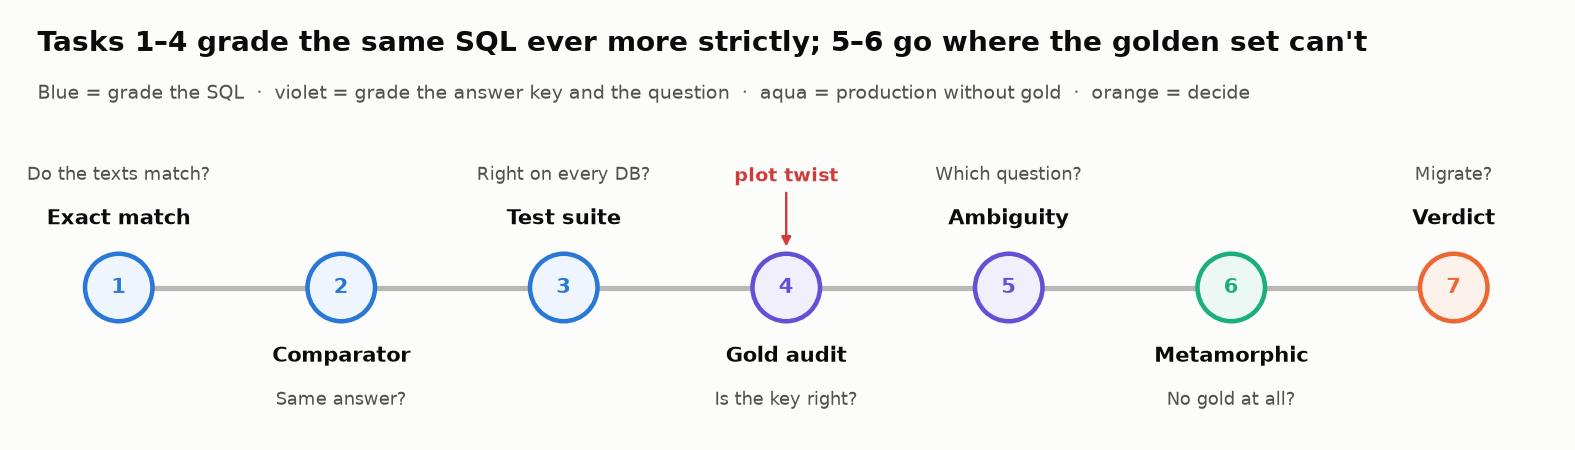

<details>
<summary>🗺️ The three acts</summary>

1. **Grade the SQL** (Tasks 1–3, Part 1)
2. **Grade the answer key, then the question** (Tasks 4–5, Part 2)
3. **Grade production, then decide** (Tasks 6–7, Part 2)
</details>

<details>
<summary>🎯 Objectives · setup</summary>

## 🎯 Learning Objectives

Grade SQL by results; write a comparator, a fuzzer and a consistency check; audit an answer key; make a paired migration call.

## 📋 Prerequisites

Module 04; reading basic SQL. The decoder below defines every bookkeeping term.

## ⏱️ Estimated Time

Part 1 ~40 min, Part 2 ~45 min; each 🏆 challenge adds 10–30.

## 🧪 Environment and Setup

Offline: SQLite in memory, recorded SQL, fixed seeds. Optional real model after Task 7.
</details>

<details><summary>📖 <b>Jargon decoder: 24 terms this lab uses (click to open)</b></summary>

| Term | Plain-English meaning | Where you'll meet it |
|---|---|---|
| **Text-to-SQL / NL2SQL** | A model writes a SQL query from a natural-language question; the database computes the answer | Everywhere |
| **Golden set** | A fixed list of test questions with agreed answers, used to score every version | Task 1 |
| **Gold SQL / answer key** | The reference query for a golden question. Its result is treated as the right answer | Task 1 |
| **Exact match (EM)** | Pass if the predicted SQL text equals the gold SQL text (after trimming spaces and case) | Task 1 |
| **Execution accuracy (EX)** | Pass if the predicted query's *result* equals the gold query's result on one database | Task 2 |
| **Result set** | The rows a query returns, e.g. `[(4200.0,)]` (one row, one column) | Task 2 |
| **Comparator** | The function that decides whether two result sets count as "the same answer" | Task 2 |
| **CTE** | A `WITH name AS (...)` block: a named sub-query, a style choice that changes the text but not the result | Task 1 |
| **Test-suite accuracy** | Pass only if the results match on *every* database in a suite of varied databases (Zhong et al., 2020) | Task 3 |
| **Fuzzer** | Code that copies a database and injects one kind of edge case (voided entries, month-end timestamps…) | Task 3 |
| **Lucky pass** | A wrong query that matches the gold on the test database because the data that would expose it isn't there | Task 3 |
| **Annotation error** | A mistake in the answer key itself | Task 4 |
| **Report engine** | The product's existing, audited report code (P&L, vendor spend). In this lab it's the trusted source for "the right number" | Task 4 |
| **Reading (interpretation)** | One valid way to understand an ambiguous question | Task 5 |
| **Metric glossary (semantic layer)** | Written definitions of business terms ("spend = bills + expenses − credits, posted only") that the model must follow | Task 5 |
| **Metamorphic test** | Check a *relation* between answers instead of each answer: Q3 total must equal July + Aug + Sep. Needs no gold | Task 6 |
| **Discordant pair** | A question one model got right and the other got wrong. Only these say anything about which is better | Task 7 |
| **McNemar test / Wilson CI** | A paired significance test on discordant pairs / a confidence interval for a pass rate (both from Lab 05b) | Task 7 |
| **Bill vs bill payment** | A *bill* records what you owe a vendor; a *bill payment* records paying it. Counting both double-counts | Task 2 |
| **Void / draft** | A voided entry was cancelled; a draft was never approved. Neither counts in any total | Task 3 |
| **Vendor credit / refund** | Money a vendor gives back (a credit) or you give a customer back (a refund). It *reduces* spend or revenue | Task 3 |
| **1099 contractor** | A self-employed person you pay for services; US businesses report payments to them on Form 1099-NEC | Task 5 |
| **Accrual vs cash basis** | Accrual counts an expense when the bill arrives; cash counts it when you pay | Task 5 |
| **Fiscal vs calendar quarter** | A company's fiscal year can start in any month (Harbor & Pine's starts 1 Feb), so "Q2" can mean two different date ranges | Task 5 |

</details>

## 📖 Scenario

**Ledgerly Ask** (fictional): the model writes SQL, the owner's books compute the number. Test customer: **Harbor & Pine Coffee Co.** ("today" is 15 Oct 2026).

<font color="#d03b3b"><b>⚠️ A plausible wrong number is worse than no number:</b></font> nobody re-checks a number that looks right.

The **metric glossary** (in the model's prompt) every answer must follow:

```
• spend   = bills + expenses − vendor credits, POSTED only, dated in the period (accrual basis)
• revenue = invoices + sales receipts − refunds, POSTED only, dated in the period
• a period includes its last day; quarters are calendar quarters unless the question says 'fiscal'
```

<details><summary>🗄️ The schema and the evidence on your desk</summary>

```
company(name, as_of, fiscal_year_start_month)
accounts(account_id, name, type)            -- type: Income | COGS | Expense | Asset | Liability
vendors(vendor_id, name, is_1099)           -- is_1099 = 1 for independent contractors (you file a 1099-NEC)
customers(customer_id, name)
transactions(txn_id, txn_date 'YYYY-MM-DD HH:MM:SS', txn_type, account_id, vendor_id, customer_id,
             amount (always positive), status, doc_number, ref_txn_id, memo)
   txn_type: bill | bill_payment | expense | vendor_credit | invoice | payment | sales_receipt | refund
   status:   posted | void | draft
```

**Evidence:** `golden` (50 questions; 30 golds are **v1's drafts a reviewer approved**) · `RECORDED["v1"]`, `RECORDED["v2"]` (each model's SQL) · `DEMO` (the one database CI runs on) · the gate: block if v2 trails by more than 2 points.
</details>

▶️ **Run:** the next four cells: imports · 🎨 lab kit · 🧰 lab harness (the books, 50 golden questions, both models' recorded SQL, the fuzzers) · 🧰 chart helpers. Expect three ✅ / 🎨 / 🧰 lines.

In [ ]:
# Everything below ships with Google Colab; sqlite3 is part of Python's standard library.
# Running locally? pip install pandas matplotlib
import itertools
import math
import random
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)
print("✅ Environment ready")

In [ ]:
# @title 🎨 Lab kit: insight cards, stat tiles, chart theme (run me; no need to read)
# LABKIT v2 — shared across every lab in this course. Pure Python + IPython; no installs.
# Functions you'll see used in this notebook:
#   insight(headline, body, kind="insight")   -> a callout card that states what the numbers just revealed
#   tiles([(label, value, note, status), ...])  -> a row of KPI tiles (status: good|warning|serious|critical|None)
#   verdict(decision, reasons)                  -> a SHIP / SHIP WITH CAUTION / BLOCK banner
#   style_charts()                              -> one consistent matplotlib theme (called automatically)
#   PALETTE / STATUS                            -> the colors used in every chart
#   check(label, got, expected, hint=, success=) -> grades a ✋ Your turn exercise: ✅ / ❌ + hint / ⏳ (still `...`)
#   quiz(label, choice, correct, why, wrong=)    -> grades a ❓ dropdown answer and explains it
#   todo(x)                                      -> True while an exercise blank is still `...`
#   scoreboard()                                 -> your exercise + quiz score so far, and what to revisit
import html as _html

try:
    from IPython.display import HTML as _HTML, display as _display
except ImportError:  # running as a plain script
    _HTML, _display = None, None

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
_STATUS_ICON = {"good": "✅", "warning": "⚠️", "serious": "🟠", "critical": "⛔"}

_KINDS = {
    #  kind        icon  label                    accent     tint
    "insight":    ("💡", "Insight",               "#2a78d6", "#eef5fd"),
    "surprise":   ("🤯", "Counterintuitive",      "#6250d6", "#f1effc"),
    "warning":    ("⚠️", "Watch out",             "#ec835a", "#fdf1ec"),
    "production": ("🏭", "In production",         "#1baf7a", "#ebf8f3"),
    "numbers":    ("📈", "By the numbers",        "#eda100", "#fdf6e6"),
    "research":   ("📚", "What the research says", "#52514e", "#f3f2ef"),
}


def _show(markup):
    if _display is not None:
        _display(_HTML(markup))
    else:
        import re
        print(re.sub(r"<[^>]+>", "", markup))


def _md(text):
    """Tiny formatter: **bold**, `code`, and newlines. Everything else is escaped."""
    import re
    t = _html.escape(str(text))
    t = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", t)
    t = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", t)
    t = re.sub(r"`(.+?)`", r"<code style='background:#0000000d;padding:1px 4px;border-radius:4px'>\1</code>", t)
    return t.replace("\n", "<br>")


def insight(headline, body="", kind="insight"):
    """Render a callout card. Use it right after a result to say what the result *means*."""
    icon, label, accent, tint = _KINDS.get(kind, _KINDS["insight"])
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:12px 16px;margin:10px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {label}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:4px 0 6px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def tiles(items):
    """items: list of (label, value, note, status). status in good|warning|serious|critical|None."""
    cells = []
    for item in items:
        label, value, note, status = (list(item) + [None, None, None, None])[:4]
        color = STATUS.get(status, "#d9d8d4")
        icon = _STATUS_ICON.get(status, "")
        cells.append(
            f"<div style='flex:1 1 160px;min-width:150px;background:#fcfcfb;border:1px solid #e4e3df;"
            f"border-top:4px solid {color};border-radius:8px;padding:10px 14px'>"
            f"<div style='font-size:12px;color:#52514e'>{_md(label)}</div>"
            f"<div style='font-size:26px;font-weight:700;color:#0b0b0b;margin:2px 0'>{_md(value)}</div>"
            f"<div style='font-size:12px;color:#52514e'>{icon} {_md(note or '')}</div></div>"
        )
    _show(
        "<div style='display:flex;flex-wrap:wrap;gap:10px;margin:10px 0;"
        "font-family:system-ui,-apple-system,sans-serif;max-width:900px'>" + "".join(cells) + "</div>"
    )


def verdict(decision, reasons=()):
    """decision: 'SHIP' | 'SHIP WITH CAUTION' | 'BLOCK' (anything else renders neutral)."""
    d = str(decision).upper()
    status = "good" if d == "SHIP" else "critical" if d.startswith("BLOCK") else "warning"
    icon = {"good": "🚀", "critical": "🛑", "warning": "⚠️"}[status]
    items = "".join(f"<li>{_md(r)}</li>" for r in reasons)
    _show(
        f"<div style='border:2px solid {STATUS[status]};border-radius:10px;padding:12px 18px;margin:10px 0;"
        f"background:#fcfcfb;color:#0b0b0b;font-family:system-ui,-apple-system,sans-serif;max-width:900px'>"
        f"<div style='font-size:22px;font-weight:800'>{icon} {_html.escape(d)}</div>"
        f"<ul style='margin:6px 0 0 18px;padding:0;font-size:14px;line-height:1.5'>{items}</ul></div>"
    )


def style_charts():
    """One chart theme for the whole course: thin marks, recessive grid, fixed color order."""
    try:
        import matplotlib as mpl
        from cycler import cycler
    except ImportError:
        return
    mpl.rcParams.update({
        "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
        "axes.edgecolor": "#b9b8b3", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
        "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": "#e9e8e4", "grid.linewidth": 0.8,
        "xtick.color": "#52514e", "ytick.color": "#52514e", "font.size": 11,
        "lines.linewidth": 2, "lines.markersize": 7, "legend.frameon": False,
        "axes.prop_cycle": cycler(color=PALETTE), "figure.dpi": 110,
    })


# ----------------------------------------------------------------- interactive: exercises, quizzes, score
_SCORE = {}   # label -> (kind, status) where status is "pass" | "fail" | "todo"


class _Graded(int):
    """check()/quiz() result: works like True/False (if, ==, sum) but prints nothing as a cell's last line."""
    def __repr__(self):
        return "True" if self else "False"

    def _ipython_display_(self):
        pass


def todo(x):
    """True while an exercise blank is still `...` (or None)."""
    return x is Ellipsis or x is None


def _card(icon, label, headline, body, accent, tint):
    _show(
        f"<div style='border-left:5px solid {accent};background:{tint};color:#0b0b0b;"
        f"padding:10px 16px;margin:8px 0;border-radius:8px;font-family:system-ui,-apple-system,sans-serif;"
        f"line-height:1.45;max-width:900px'>"
        f"<div style='font-size:11px;letter-spacing:.08em;text-transform:uppercase;color:#52514e;"
        f"font-weight:600'>{icon} {_md(label)}</div>"
        f"<div style='font-size:16px;font-weight:650;margin:3px 0 4px'>{_md(headline)}</div>"
        f"<div style='font-size:14px;color:#2b2b2a'>{_md(body)}</div></div>"
    )


def _same(got, expected, tol):
    try:
        import numpy as _np
        if isinstance(got, (_np.generic,)):
            got = got.item()
        if isinstance(expected, (_np.generic,)):
            expected = expected.item()
    except ImportError:
        pass
    if isinstance(expected, bool) or isinstance(got, bool):
        return got == expected
    if isinstance(expected, (int, float)) and isinstance(got, (int, float)):
        return abs(float(got) - float(expected)) <= tol * max(1.0, abs(float(expected)))
    if isinstance(expected, str) and isinstance(got, str):
        return got.strip().lower() == expected.strip().lower()
    if isinstance(expected, (set, frozenset)) or isinstance(got, (set, frozenset)):
        try:
            return set(got) == set(expected)
        except TypeError:
            return False
    return got == expected


def check(label, got, expected=None, *, ok=None, tol=1e-6, hint="", success="", reveal=False):
    """Grade a ✋ Your turn exercise.

    got:      the learner's answer (still `...` = not attempted yet: shows ⏳, never an error)
    expected: the reference answer (compared with tolerance for numbers, case-insensitively for strings)
    ok:       pass a bool instead of `expected` for custom rules (e.g. ok=my_case_fools_the_grader)
    reveal:   show the expected answer on a wrong attempt (default False: the hint teaches, the answer spoils)
    """
    if todo(got):
        _SCORE[label] = ("exercise", "todo")
        _card("⏳", f"Your turn · {label}", "Not attempted yet",
              "Replace the `...` above with your answer and re-run this cell. "
              "The lab keeps going with the reference answer, so later cells still work.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    try:
        passed = bool(ok) if ok is not None else _same(got, expected, tol)
    except Exception:
        passed = False
    _SCORE[label] = ("exercise", "pass" if passed else "fail")
    if passed:
        _card("✅", f"Correct · {label}", success or "Nice. That matches the reference.", "", "#0ca30c", "#ecf8ec")
    else:
        shown = f"You got `{got!r}`" + (f"; expected `{expected!r}`" if reveal and ok is None and expected is not None else "") + "."
        _card("❌", f"Not yet · {label}", shown, (f"💡 Hint: {hint}" if hint else "Re-read the step above and try again."),
              "#d03b3b", "#fcefef")
    return _Graded(passed)


def quiz(label, choice, correct, why, wrong=None):
    """Grade a ❓ dropdown answer. choice: the @param string, e.g. "B) The average hides it".
    correct: the letter ("B"). why: the explanation (shown once answered). wrong: {letter: feedback for that pick}."""
    pick = str(choice).strip()[:1].upper()
    if not pick.isalpha():
        _SCORE[label] = ("quiz", "todo")
        _card("❓", f"Quick check · {label}", "Pick an answer in the dropdown, then run this cell.",
              "Commit before you scroll: a guess you wrote down is what makes the next result stick.", "#9a9893", "#f3f2ef")
        return _Graded(False)
    passed = pick == str(correct).strip()[:1].upper()
    _SCORE[label] = ("quiz", "pass" if passed else "fail")
    extra = (wrong or {}).get(pick, "")
    if passed:
        _card("✅", f"Quick check · {label}", f"Right: {correct}.", why, "#0ca30c", "#ecf8ec")
    else:
        _card("🔁", f"Quick check · {label}", f"Not quite: you picked {pick}, the answer is {correct}.",
              (extra + "\n" if extra else "") + why, "#ec835a", "#fdf1ec")
    return _Graded(passed)


def scoreboard():
    """Your score on every ✋ exercise and ❓ quick check you've run, plus what to revisit."""
    ex = [s for k, s in _SCORE.values() if k == "exercise"]
    qz = [s for k, s in _SCORE.values() if k == "quiz"]
    redo = [lbl for lbl, (_, s) in _SCORE.items() if s != "pass"]
    tiles([
        ("✋ Exercises solved", f"{ex.count('pass')}/{len(ex)}", f"{ex.count('todo')} not attempted",
         "good" if ex and ex.count("pass") == len(ex) else "warning"),
        ("❓ Quick checks right", f"{qz.count('pass')}/{len(qz)}", f"{qz.count('todo')} unanswered",
         "good" if qz and qz.count("pass") == len(qz) else "warning"),
    ])
    if redo:
        insight("Worth a second pass", "\n".join(f"• {r}" for r in redo), kind="warning")
    elif _SCORE:
        insight("Clean sweep", "Every exercise and quick check correct. Try the 🏆 challenges next.", kind="insight")


style_charts()
print("🎨 Lab kit loaded: insight(), tiles(), verdict(), check(), quiz(), scoreboard()")

In [ ]:
# @title 🧰 Lab harness: Harbor & Pine's books, the golden set, recorded SQL, 7 fuzzers, reference answers (hidden · 860 lines · holds the exercise answers, so expand after you've tried)
# ============================================================
# 🧰 LAB HARNESS: the "infrastructure" for this lab
# ============================================================
# Builds everything you'll USE but don't need to write:
#   1. make_demo_db()   the CI demo database: one year of Harbor & Pine Coffee Co.'s books (sqlite, in memory)
#   2. golden           the 50-question golden set CI scores against (question, gold SQL, who wrote the gold)
#   3. RECORDED         the SQL each model wrote for each golden question (v1 = incumbent, v2 = candidate)
#   4. run_sql()        execute SQL safely and return rows (or an error string)
#   5. FUZZERS          functions that copy the demo DB and inject one kind of edge case
#   6. report_engine()  the books' audited report engine: the "trusted number" for a question (Task 4)
#   7. ambiguous / production question sets for Tasks 5 and 6
#   8. Reference solutions (names start with _reference_) used as safety nets for the exercises.
# Everything is generated from fixed seeds, so the whole class sees the same numbers.
# ============================================================
import calendar as _cal
import datetime as _dt
import itertools as _it
import math
import random as _random
import re as _re
import sqlite3

import pandas as pd

AS_OF = "2026-10-15"            # "today" in the books (stored in company.as_of)
FY_START_MONTH = 2              # Harbor & Pine's fiscal year starts 1 February

_ACCOUNTS = [  # (id, name, type)
    (1, "Coffee Sales", "Income"), (2, "Wholesale Sales", "Income"), (3, "Merch Sales", "Income"),
    (10, "Green Coffee", "COGS"), (11, "Packaging", "COGS"),
    (20, "Rent", "Expense"), (21, "Payroll", "Expense"), (22, "Contract Labor", "Expense"),
    (23, "Utilities", "Expense"), (24, "Marketing", "Expense"), (25, "Software", "Expense"),
    (26, "Repairs & Maintenance", "Expense"), (27, "Equipment Rental", "Expense"), (29, "Meals", "Expense"),
    (40, "Checking", "Asset"), (41, "Accounts Receivable", "Asset"), (50, "Accounts Payable", "Liability"),
]
_VENDORS = [  # (id, name, is_1099, account_id, (low, high) amount, bills per month, kind)
    (1, "Verde Importers", 0, 10, (900, 2600), 2, "bill"),
    (2, "Mercato Packaging", 0, 11, (180, 620), 2, "bill"),
    (3, "Pine Street Properties LLC", 0, 20, (4200, 4200), 1, "bill"),
    (4, "Brightwage Payroll", 0, 21, (6800, 9400), 2, "expense"),
    (5, "Tidewater Staffing Inc.", 0, 22, (3000, 6000), 1, "bill"),
    (6, "Marco Diaz", 1, 22, (320, 880), 2, "bill"),
    (7, "Ana Sousa Bookkeeping", 1, 22, (450, 450), 1, "bill"),
    (8, "Rivera Plumbing", 1, 26, (140, 980), 1, "bill"),
    (9, "Lena Park Design", 1, 24, (600, 2400), 1, "bill"),
    (10, "Harborlight Utilities", 0, 23, (380, 760), 1, "bill"),
    (11, "Cloudtill POS", 0, 25, (89, 89), 1, "expense"),
    (12, "Coastal Equipment Rentals", 0, 27, (210, 540), 1, "bill"),
    (13, "Mercato Market", 0, 29, (25, 140), 3, "expense"),
    (14, "Gulls & Grain Print Shop", 0, 24, (120, 480), 1, "expense"),
]
_CUSTOMERS = [(1, "Driftwood Cafe"), (2, "Saltmarsh Grocery"), (3, "Ferry Kiosk"), (4, "Lighthouse Inn")]

_SCHEMA = """
CREATE TABLE company (name TEXT, as_of TEXT, fiscal_year_start_month INTEGER);
CREATE TABLE accounts (account_id INTEGER PRIMARY KEY, name TEXT, type TEXT);
CREATE TABLE vendors (vendor_id INTEGER PRIMARY KEY, name TEXT, is_1099 INTEGER);
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, name TEXT);
CREATE TABLE transactions (
  txn_id INTEGER PRIMARY KEY, txn_date TEXT, txn_type TEXT, account_id INTEGER, vendor_id INTEGER,
  customer_id INTEGER, amount REAL, status TEXT, doc_number TEXT, ref_txn_id INTEGER, memo TEXT);
"""
SCHEMA_DOC = """company(name, as_of, fiscal_year_start_month)
accounts(account_id, name, type)            -- type: Income | COGS | Expense | Asset | Liability
vendors(vendor_id, name, is_1099)           -- is_1099 = 1 for independent contractors (you file a 1099-NEC)
customers(customer_id, name)
transactions(txn_id, txn_date 'YYYY-MM-DD HH:MM:SS', txn_type, account_id, vendor_id, customer_id,
             amount (always positive), status, doc_number, ref_txn_id, memo)
   txn_type: bill | bill_payment | expense | vendor_credit | invoice | payment | sales_receipt | refund
   status:   posted | void | draft"""
GLOSSARY = """Harbor & Pine metric definitions (the 'house rules' every answer must follow):
• spend      = bills + expenses − vendor credits, POSTED only, dated in the period (accrual basis)
• revenue    = invoices + sales receipts − refunds, POSTED only, dated in the period
• a period includes its last day; quarters are calendar quarters unless the question says 'fiscal'"""


def _ts(d, rng, late=False):
    h = 23 if late else rng.randint(8, 17)
    return f"{d.isoformat()} {h:02d}:{59 if late else rng.randint(0, 59):02d}:{rng.randint(0, 59):02d}"


def _months(start=(2025, 11), n=12):
    y, m = start
    for _ in range(n):
        yield y, m
        m += 1
        if m == 13:
            y, m = y + 1, 1


def make_demo_db(seed=2026):
    """The CI demo database: Nov 2025 → 14 Oct 2026. Mostly tidy books, as demo data usually is."""
    rng = _random.Random(seed)
    con = sqlite3.connect(":memory:")
    con.executescript(_SCHEMA)
    con.execute("INSERT INTO company VALUES ('Harbor & Pine Coffee Co.', ?, ?)", (AS_OF, FY_START_MONTH))
    con.executemany("INSERT INTO accounts VALUES (?,?,?)", _ACCOUNTS)
    con.executemany("INSERT INTO vendors VALUES (?,?,?)", [(v[0], v[1], v[2]) for v in _VENDORS])
    con.executemany("INSERT INTO customers VALUES (?,?)", _CUSTOMERS)
    rows, tid = [], 1000
    as_of = _dt.date.fromisoformat(AS_OF)

    def add(**r):
        nonlocal tid
        tid += 1
        base = dict(txn_id=tid, vendor_id=None, customer_id=None, status="posted", doc_number=None,
                    ref_txn_id=None, memo=None)
        base.update(r)
        rows.append(base)
        return tid

    for y, m in _months():
        last = _cal.monthrange(y, m)[1]
        for vid, name, is1099, acct, (lo, hi), per_month, kind in _VENDORS:
            for _ in range(per_month):
                d = _dt.date(y, m, rng.randint(1, last - 3))
                if d >= as_of:
                    continue
                amt = round(rng.uniform(lo, hi), 2) if lo != hi else float(lo)
                status = "void" if rng.random() < 0.025 else "draft" if rng.random() < 0.015 else "posted"
                t = add(txn_date=_ts(d, rng), txn_type=kind, account_id=acct, vendor_id=vid, amount=amt,
                        status=status, doc_number=f"B-{tid + 1}")
                if kind == "bill" and status == "posted":
                    pd_ = d + _dt.timedelta(days=rng.randint(8, 45))
                    if pd_ < as_of:
                        add(txn_date=_ts(pd_, rng), txn_type="bill_payment", account_id=acct, vendor_id=vid,
                            amount=amt, ref_txn_id=t)
        # a few card expenses with no vendor on file (common in real books)
        if rng.random() < 0.25:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="expense", account_id=29, amount=round(rng.uniform(12, 60), 2),
                    memo="card swipe, no vendor")
        # rare vendor credit
        if rng.random() < 0.12:
            v = rng.choice([1, 2, 12])
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                acct = [x for x in _VENDORS if x[0] == v][0][3]
                add(txn_date=_ts(d, rng), txn_type="vendor_credit", account_id=acct, vendor_id=v,
                    amount=round(rng.uniform(40, 220), 2), memo="damaged goods credit")
        # revenue: weekly café sales receipts, monthly wholesale invoices
        for wk in range(4):
            d = _dt.date(y, m, min(last - 3, 2 + 7 * wk))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=1,
                    amount=round(rng.uniform(5200, 7900), 2))
                if rng.random() < 0.5:
                    add(txn_date=_ts(d, rng), txn_type="sales_receipt", account_id=3,
                        amount=round(rng.uniform(180, 640), 2))
        for cid, _cname in _CUSTOMERS:
            if cid == 4 and rng.random() < 0.5:
                continue
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d >= as_of:
                continue
            amt = round(rng.uniform(800, 3200), 2)
            st = "void" if rng.random() < 0.03 else "posted"
            t = add(txn_date=_ts(d, rng), txn_type="invoice", account_id=2, customer_id=cid, amount=amt,
                    status=st, doc_number=f"INV-{tid + 1}")
            pdate = d + _dt.timedelta(days=rng.randint(10, 50))
            if st == "posted" and pdate < as_of and rng.random() < 0.85:
                add(txn_date=_ts(pdate, rng), txn_type="payment", account_id=41, customer_id=cid, amount=amt,
                    ref_txn_id=t)
        if rng.random() < 0.1:
            d = _dt.date(y, m, rng.randint(1, last - 3))
            if d < as_of:
                add(txn_date=_ts(d, rng), txn_type="refund", account_id=2, customer_id=rng.choice([1, 2, 3]),
                    amount=round(rng.uniform(60, 300), 2), memo="returned bags")
    con.executemany("INSERT INTO transactions VALUES (:txn_id,:txn_date,:txn_type,:account_id,:vendor_id,"
                    ":customer_id,:amount,:status,:doc_number,:ref_txn_id,:memo)", rows)
    con.commit()
    return con


def clone_db(con):
    new = sqlite3.connect(":memory:")
    con.backup(new)
    return new


def run_sql(con, sql):
    """Execute SQL; return a list of row tuples, or 'ERROR: …' (models write broken SQL sometimes)."""
    try:
        return [tuple(r) for r in con.execute(sql).fetchall()]
    except sqlite3.Error as e:
        return f"ERROR: {e}"


# ---------------------------------------------------------------- periods
def _q(y, q):
    s = _dt.date(y, 3 * q - 2, 1)
    e = _dt.date(y, 3 * q, _cal.monthrange(y, 3 * q)[1])
    return (f"Q{q} {y}", s.isoformat(), e.isoformat())


def _m(y, m):
    return (_dt.date(y, m, 1).strftime("%B %Y"), _dt.date(y, m, 1).isoformat(),
            _dt.date(y, m, _cal.monthrange(y, m)[1]).isoformat())


def _next_day(iso):
    return (_dt.date.fromisoformat(iso) + _dt.timedelta(days=1)).isoformat()


# ---------------------------------------------------------------- SQL writers
# Three "authors" write SQL in their own style: the reviewer ("rev"), the incumbent model ("v1"),
# and the candidate model ("v2"). A mode other than "ok" plants one realistic bug.
_SPEND_TYPES = "('bill', 'expense', 'vendor_credit')"


def _sum_expr(mode, sign_type, alias=""):
    a = f"{alias}." if alias else ""
    if mode == "CREDIT":                                # forgets that credits/refunds reduce the total
        return f"SUM({a}amount)"
    return f"SUM(CASE WHEN {a}txn_type = '{sign_type}' THEN -{a}amount ELSE {a}amount END)"


def _types(mode, kind):
    if kind == "spend":
        return "('bill', 'expense', 'bill_payment', 'vendor_credit')" if mode == "DOUBLE" else _SPEND_TYPES
    return "('invoice', 'sales_receipt', 'payment', 'refund')" if mode == "DOUBLE" else "('invoice', 'sales_receipt', 'refund')"


def _date_v1(mode, s, e, a=""):
    p = f"{a}." if a else ""
    if mode == "BOUNDARY":                              # string BETWEEN on a timestamp drops the last day
        return f"{p}txn_date BETWEEN '{s}' AND '{e}'"
    return f"date({p}txn_date) BETWEEN '{s}' AND '{e}'"


def _date_v2(mode, s, e, a="t"):
    if mode == "BOUNDARY":
        return f"{a}.txn_date >= '{s}' AND {a}.txn_date <= '{e}'"
    return f"{a}.txn_date >= '{s}' AND {a}.txn_date < '{_next_day(e)}'"


def _status(mode, a=""):
    p = f"{a}." if a else ""
    return "" if mode == "VOID" else f" AND {p}status = 'posted'"


def sql_filtered_total(kind, dim, name, period, mode="ok", style="rev"):
    """Spend on an account / with a vendor, or revenue from a customer, in a period."""
    _, s, e = period
    sign = "vendor_credit" if kind == "spend" else "refund"
    table, key = {"account": ("accounts", "account_id"), "vendor": ("vendors", "vendor_id"),
                  "customer": ("customers", "customer_id")}[dim]
    like = mode == "LIKE"
    match = f"LIKE '{name.split()[0]}%'" if like else f"= '{name}'"
    if mode == "NOFILTER":                              # answers for every account/vendor/customer at once
        if style == "v2":
            return (f"WITH q AS (\n  SELECT x.name, t.amount, t.txn_type FROM transactions t\n"
                    f"  JOIN {table} x ON x.{key} = t.{key}\n"
                    f"  WHERE t.status = 'posted' AND t.txn_type IN {_types('ok', kind)}\n"
                    f"    AND {_date_v2('ok', s, e)})\n"
                    f"SELECT name, ROUND({_sum_expr('ok', sign)}, 2) AS total FROM q GROUP BY name")
        return (f"SELECT x.name, ROUND({_sum_expr('ok', sign, 't')}, 2) FROM transactions t "
                f"JOIN {table} x ON x.{key} = t.{key} WHERE t.status = 'posted' AND t.txn_type IN "
                f"{_types('ok', kind)} AND {_date_v1('ok', s, e, 't')} GROUP BY x.name")
    if style == "rev":
        join_v = " JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
        return (f"SELECT ROUND(COALESCE({_sum_expr(mode, sign, 't')}, 0), 2) AS {kind}\n"
                f"FROM transactions t\nJOIN {table} x ON x.{key} = t.{key}{join_v}\n"
                f"WHERE x.name {match}{_status(mode, 't')}\n"
                f"  AND t.txn_type IN {_types(mode, kind)}\n"
                f"  AND {_date_v1(mode, s, e, 't')}")
    if style == "v1":
        join_v = " JOIN vendors USING (vendor_id)" if mode == "JOIN" else ""
        sub = f"(SELECT {key} FROM {table} WHERE name {match})"
        op = "IN" if like else "="
        return (f"SELECT ROUND({_sum_expr(mode, sign)}, 2) FROM transactions{join_v} "
                f"WHERE {key} {op} {sub}{_status(mode)} AND txn_type IN {_types(mode, kind)} "
                f"AND {_date_v1(mode, s, e)}")
    # v2: CTE, half-open date range, sometimes no ROUND
    join_v = "\n  JOIN vendors v ON v.vendor_id = t.vendor_id" if mode == "JOIN" else ""
    st = "" if mode == "VOID" else "t.status = 'posted' AND "
    return (f"WITH q AS (\n  SELECT t.amount, t.txn_type\n  FROM transactions t\n"
            f"  JOIN {table} x ON x.{key} = t.{key}{join_v}\n"
            f"  WHERE x.name {match} AND {st}t.txn_type IN {_types(mode, kind)}\n"
            f"    AND {_date_v2(mode, s, e)}\n)\n"
            f"SELECT {_sum_expr(mode, sign)} AS total_{kind} FROM q")


def sql_last_month(account, mode="ok", style="rev"):
    """Spend on an account 'last month', relative to company.as_of."""
    sign = "vendor_credit"
    if mode == "MONTH":   # the classic: month(today) - 1 (returns nothing in January)
        win = ("CAST(strftime('%m', t.txn_date) AS INTEGER) = CAST(strftime('%m', c.as_of) AS INTEGER) - 1\n"
               "  AND strftime('%Y', t.txn_date) = strftime('%Y', c.as_of)")
    elif style == "v2":
        win = ("t.txn_date >= date(c.as_of, 'start of month', '-1 month')\n"
               "  AND t.txn_date < date(c.as_of, 'start of month')")
    else:
        win = ("date(t.txn_date) BETWEEN date(c.as_of, 'start of month', '-1 month')\n"
               "  AND date(c.as_of, 'start of month', '-1 day')")
    st = "" if mode == "VOID" else " AND t.status = 'posted'"
    head = "ROUND(COALESCE(" + _sum_expr(mode, sign, "t") + ", 0), 2)" if style != "v2" else _sum_expr(mode, sign, "t")
    return (f"SELECT {head} AS spend\nFROM transactions t\nJOIN accounts a ON a.account_id = t.account_id\n"
            f"CROSS JOIN company c\nWHERE a.name = '{account}'{st}\n  AND t.txn_type IN {_types(mode, 'spend')}\n"
            f"  AND {win}")


def sql_breakdown(account, period, mode="ok", style="rev"):
    """Monthly spend on an account within a quarter: rows of (month, total)."""
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":   # different column order, no ORDER BY
        return (f"SELECT {_sum_expr(mode, sign, 't')} AS total, strftime('%Y-%m', t.txn_date) AS month\n"
                f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id\n"
                f"WHERE a.name = '{account}'{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')}\n"
                f"  AND {_date_v2(mode, s, e)}\nGROUP BY month")
    return (f"SELECT strftime('%Y-%m', t.txn_date) AS month, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend "
            f"FROM transactions t JOIN accounts a ON a.account_id = t.account_id WHERE a.name = '{account}'"
            f"{_status(mode, 't')} AND t.txn_type IN {_types(mode, 'spend')} AND {_date_v1(mode, s, e, 't')} "
            f"GROUP BY month ORDER BY month")


def sql_list_1099(mode="ok", style="rev"):
    if mode == "NOFILTER":
        return "SELECT name FROM vendors ORDER BY name"
    if style == "v2":
        return "SELECT name AS contractor FROM vendors WHERE is_1099 = 1"
    return "SELECT name FROM vendors WHERE is_1099 = 1 ORDER BY name"


def sql_top_vendors(n, period, mode="ok", style="rev"):
    _, s, e = period
    sign = "vendor_credit"
    if style == "v2":
        return (f"WITH spend AS (\n  SELECT v.name, {_sum_expr(mode, sign, 't')} AS total\n"
                f"  FROM transactions t JOIN vendors v ON v.vendor_id = t.vendor_id\n"
                f"  WHERE {'' if mode == 'VOID' else 't.status = ' + chr(39) + 'posted' + chr(39) + ' AND '}"
                f"t.txn_type IN {_types(mode, 'spend')}\n    AND {_date_v2(mode, s, e)}\n  GROUP BY v.name)\n"
                f"SELECT name, ROUND(total, 2) FROM spend ORDER BY total DESC LIMIT {n}")
    return (f"SELECT v.name, ROUND({_sum_expr(mode, sign, 't')}, 2) AS spend FROM transactions t "
            f"JOIN vendors v ON v.vendor_id = t.vendor_id WHERE t.txn_type IN {_types(mode, 'spend')}"
            f"{_status(mode, 't')} AND {_date_v1(mode, s, e, 't')} GROUP BY v.name ORDER BY spend DESC LIMIT {n}")


def sql_open_balance(doc, mode="ok", style="rev"):
    if mode == "NOPAY":
        return f"SELECT amount FROM transactions WHERE doc_number = '{doc}'"
    return (f"SELECT ROUND(i.amount - COALESCE(SUM(p.amount), 0), 2) AS open_balance FROM transactions i "
            f"LEFT JOIN transactions p ON p.ref_txn_id = i.txn_id AND p.txn_type = 'payment' AND p.status = 'posted' "
            f"WHERE i.doc_number = '{doc}' GROUP BY i.txn_id")


# ---------------------------------------------------------------- fuzzers (test-suite databases)
# Each fuzzer copies the demo books and injects ONE kind of edge case that real books contain.
def _next_id(con):
    return con.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0] + 1


def _insert(con, rows):
    con.executemany("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)", rows)
    con.commit()


def _reference_fuzz_void_and_draft(con, rng):
    """Copy ~1 in 4 posted bills / expenses / invoices / sales receipts as VOID or DRAFT duplicates."""
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions "
                      "WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt') "
                      "ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt in src:
        if rng.random() < 0.25:
            rows.append((nid, d, typ, acct, vid, cid, round(amt * rng.uniform(0.5, 1.5), 2),
                         rng.choice(["void", "draft"]), None, None, "entered twice / not approved"))
            nid += 1
    _insert(con, rows)


def fuzz_last_day(con, rng):
    """A late-evening transaction on the LAST day of every month, for every vendor and customer."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        last = _dt.date(y, m, _cal.monthrange(y, m)[1])
        if last >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(last, rng, late=True), kind, acct, vid, None, round(rng.uniform(lo, hi) / 3, 2),
                         "posted", None, None, "month-end"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(last, rng, late=True), "invoice", 2, None, cid, round(rng.uniform(300, 900), 2),
                         "posted", None, None, "month-end"))
            nid += 1
    _insert(con, rows)


def fuzz_credits(con, rng):
    """Vendor credits and customer refunds in every month (returns, damaged goods, overbilling)."""
    nid, rows = _next_id(con), []
    for y, m in _months():
        d = _dt.date(y, m, 14)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for vid, _n, _f, acct, (lo, hi), _p, kind in _VENDORS:
            rows.append((nid, _ts(d, rng), "vendor_credit", acct, vid, None, round(rng.uniform(lo, hi) / 5, 2),
                         "posted", None, None, "credit memo"))
            nid += 1
        for cid, _c in _CUSTOMERS:
            rows.append((nid, _ts(d, rng), "refund", 2, None, cid, round(rng.uniform(50, 250), 2),
                         "posted", None, None, "refund"))
            nid += 1
    _insert(con, rows)


def fuzz_sibling_vendors(con, rng):
    """For every vendor, a different vendor whose name starts with the same word (and that we also pay)."""
    nid, rows = _next_id(con), []
    for vid, name, _f, acct, (lo, hi), _p, kind in _VENDORS:
        sib = 100 + vid
        con.execute("INSERT INTO vendors VALUES (?,?,0)", (sib, f"{name.split()[0]} Wholesale Club"))
        for y, m in _months():
            d = _dt.date(y, m, 9)
            if d < _dt.date.fromisoformat(AS_OF):
                rows.append((nid, _ts(d, rng), "expense", 29, sib, None, round(rng.uniform(60, 400), 2),
                             "posted", None, None, "supplies"))
                nid += 1
    _insert(con, rows)


def fuzz_no_vendor(con, rng):
    """Card expenses with no vendor on file, on every expense account, every month."""
    nid, rows = _next_id(con), []
    accts = [a for a, _n, t in _ACCOUNTS if t in ("Expense", "COGS")]
    for y, m in _months():
        d = _dt.date(y, m, 6)
        if d >= _dt.date.fromisoformat(AS_OF):
            continue
        for a in accts:
            rows.append((nid, _ts(d, rng), "expense", a, None, None, round(rng.uniform(15, 120), 2),
                         "posted", None, None, "card swipe, no vendor"))
            nid += 1
    _insert(con, rows)


def fuzz_january_clock(con, rng):
    """Move 'today' to 15 Jan 2027 and add December 2026 activity (copied from December 2025)."""
    con.execute("UPDATE company SET as_of = '2027-01-15'")
    src = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount, status FROM transactions "
                      "WHERE txn_date >= '2025-12-01' AND txn_date < '2026-01-01' ORDER BY txn_id").fetchall()
    nid, rows = _next_id(con), []
    for d, typ, acct, vid, cid, amt, st in src:
        rows.append((nid, "2026" + d[4:], typ, acct, vid, cid, round(amt * rng.uniform(0.8, 1.2), 2), st, None, None,
                     "copied forward"))
        nid += 1
    _insert(con, rows)


def fuzz_jitter(con, rng):
    """Re-draw every amount (×0.5–1.5) so coincidental equalities in the demo data disappear."""
    ids = [r[0] for r in con.execute("SELECT txn_id FROM transactions ORDER BY txn_id")]
    con.executemany("UPDATE transactions SET amount = ROUND(amount * ?, 2) WHERE txn_id = ?",
                    [(rng.uniform(0.5, 1.5), i) for i in ids])
    con.commit()


FUZZERS = {"void_and_draft": _reference_fuzz_void_and_draft, "last_day": fuzz_last_day, "credits": fuzz_credits,
           "sibling_vendors": fuzz_sibling_vendors, "no_vendor": fuzz_no_vendor,
           "january_clock": fuzz_january_clock, "jitter": fuzz_jitter}


def build_suite(fuzzers=None, seed=7):
    """Demo DB + one fuzzed copy per fuzzer + one copy with ALL fuzzers applied ('kitchen_sink')."""
    fuzzers = fuzzers or FUZZERS
    demo = make_demo_db()
    suite = {"demo": demo}
    for i, (name, fn) in enumerate(fuzzers.items()):
        db = clone_db(demo)
        fn(db, _random.Random(seed * 100 + i))
        suite[name] = db
    sink = clone_db(demo)
    for i, (name, fn) in enumerate(fuzzers.items()):
        if name != "jitter":
            fn(sink, _random.Random(seed * 1000 + i))
    suite["kitchen_sink"] = sink
    return suite
_SPEC = [  # (template, args, v1 mode, v2 mode, gold written by, reviewer's mode)
    ('vendor_spend', ('Pine Street Properties LLC', 'M4'), 'ok', 'DOUBLE', 'v1 draft', None),
    ('account_spend', ('Meals', 'H1'), 'JOIN', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M9'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Pine Street Properties LLC', 'M9'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'M6'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Green Coffee', 'M4'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1312',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Marco Diaz', 'Q2'), 'LIKE', 'ok', 'reviewer', 'ok'),
    ('last_month', ('Payroll',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('breakdown', ('Repairs & Maintenance', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'M8'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Repairs & Maintenance', 'M8'), 'CREDIT', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'Q3'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Ana Sousa Bookkeeping', 'M8'), 'ok', 'VOID', 'v1 draft', None),
    ('breakdown', ('Payroll', 'Q2'), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Coastal Equipment Rentals', 'M7'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('top_vendors', (3, 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('last_month', ('Contract Labor',), 'ok', 'ok', 'v1 draft', None),
    ('list_1099', (), 'NOFILTER', 'NOFILTER', 'reviewer', 'ok'),
    ('vendor_spend', ('Cloudtill POS', 'Q1'), 'VOID', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Ferry Kiosk', 'Q1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Rent', 'Q3'), 'DOUBLE', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M6'), 'LIKE', 'ok', 'v1 draft', None),
    ('breakdown', ('Utilities', 'Q1'), 'DOUBLE', 'VOID', 'reviewer', 'ok'),
    ('account_spend', ('Contract Labor', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Verde Importers', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('open_balance', ('INV-1356',), 'ok', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Tidewater Staffing Inc.', 'Q2'), 'DOUBLE', 'DOUBLE', 'reviewer', 'ok'),
    ('account_spend', ('Marketing', 'Q1'), 'ok', 'BOUNDARY', 'v1 draft', None),
    ('vendor_spend', ('Harborlight Utilities', 'M6'), 'NOFILTER', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Lighthouse Inn', 'M7'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M1'), 'NOFILTER', 'DOUBLE', 'reviewer', 'ok'),
    ('vendor_spend', ('Rivera Plumbing', 'Q3'), 'VOID', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Cloudtill POS', 'M9'), 'CREDIT', 'ok', 'v1 draft', None),
    ('last_month', ('Meals',), 'ok', 'ok', 'reviewer', 'MONTH'),
    ('account_spend', ('Marketing', 'M9'), 'ok', 'NOFILTER', 'v1 draft', None),
    ('open_balance', ('INV-1088',), 'ok', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Driftwood Cafe', 'M2'), 'BOUNDARY', 'ok', 'v1 draft', None),
    ('breakdown', ('Contract Labor', 'Q3'), 'ok', 'ok', 'v1 draft', None),
    ('customer_revenue', ('Driftwood Cafe', 'H1'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Utilities', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('last_month', ('Equipment Rental',), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Equipment Rental', 'M6'), 'BOUNDARY', 'ok', 'reviewer', 'ok'),
    ('customer_revenue', ('Saltmarsh Grocery', 'Q3'), 'VOID', 'ok', 'reviewer', 'ok'),
    ('vendor_spend', ('Mercato Market', 'M5'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Software', 'M1'), 'ok', 'ok', 'v1 draft', None),
    ('top_vendors', (3, 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Packaging', 'M9'), 'ok', 'ok', 'v1 draft', None),
    ('vendor_spend', ('Gulls & Grain Print Shop', 'Q2'), 'ok', 'ok', 'v1 draft', None),
    ('account_spend', ('Meals', 'M5'), 'ok', 'ok', 'v1 draft', None),
]

PERIODS = {**{f"Q{q}": _q(2026, q) for q in (1, 2, 3)}, **{f"M{m}": _m(2026, m) for m in range(1, 10)},
           "H1": ("the first half of 2026", "2026-01-01", "2026-06-30")}
_TEXT = {
    "account_spend": "How much did we spend on {0} in {p}?",
    "vendor_spend": "How much did we spend with {0} in {p}?",
    "customer_revenue": "How much revenue did {0} bring in during {p}?",
    "last_month": "What did we spend on {0} last month?",
    "breakdown": "Break down {0} spend by month for {p}.",
    "top_vendors": "Who were our top {0} vendors by spend in {p}?",
    "list_1099": "Which of our vendors are 1099 contractors?",
    "open_balance": "What's the open balance on invoice {0}?",
}


def write_sql(template, args, mode="ok", style="rev"):
    """Write the SQL an author would produce for a question. mode='ok' is correct; other modes plant a bug."""
    if template in ("account_spend", "vendor_spend", "customer_revenue"):
        kind = "revenue" if template == "customer_revenue" else "spend"
        dim = template.split("_")[0]
        return sql_filtered_total(kind, dim, args[0], PERIODS[args[1]], mode, style)
    if template == "last_month":
        return sql_last_month(args[0], mode, style)
    if template == "breakdown":
        return sql_breakdown(args[0], PERIODS[args[1]], mode, style)
    if template == "top_vendors":
        return sql_top_vendors(args[0], PERIODS[args[1]], mode, style)
    if template == "list_1099":
        return sql_list_1099(mode, style)
    return sql_open_balance(args[0], mode, style)


def question_text(template, args):
    p = PERIODS[args[1]][0] if len(args) > 1 and args[1] in PERIODS else None
    return _TEXT[template].format(*args, p=p)


_rows, RECORDED, _TRUTH_SQL = [], {"v1": {}, "v2": {}}, {}
for _i, (_t, _a, _m1, _m2, _by, _gm) in enumerate(_SPEC, start=1):
    _qid = f"G{_i:02d}"
    RECORDED["v1"][_qid] = write_sql(_t, _a, _m1, "v1")
    RECORDED["v2"][_qid] = write_sql(_t, _a, _m2, "v2")
    _TRUTH_SQL[_qid] = write_sql(_t, _a, "ok", "rev")
    _gold = RECORDED["v1"][_qid] if _by == "v1 draft" else write_sql(_t, _a, _gm, "rev")
    _rows.append({"qid": _qid, "question": question_text(_t, _a), "template": _t, "gold_sql": _gold,
                  "gold_written_by": _by, "ordered": _t == "top_vendors"})
golden = pd.DataFrame(_rows).set_index("qid")


def report_engine(qid, con):
    """The books' audited report engine: the trusted number for a golden question (used from Task 4 on).
    In a real product this is the existing P&L / vendor / A/R report code that accountants already reconcile."""
    return run_sql(con, _TRUTH_SQL[qid])


# ---------------------------------------------------------------- comparators
def normalize_sql(sql):
    """For exact match: lower-case, collapse whitespace, drop a trailing semicolon."""
    return _re.sub(r"\s+", " ", sql.strip().rstrip(";").lower())


def strict_match(pred, gold, ordered=False):
    """What CI does today: Python == on the raw rows."""
    return pred == gold


def lenient_match(pred, gold, ordered=False):
    """Over-lenient: pass if every gold value shows up somewhere in the predicted rows."""
    if isinstance(pred, str) or isinstance(gold, str):
        return False
    seen = {round(c, 2) if isinstance(c, float) else c for r in pred for c in r}
    return all((round(c, 2) if isinstance(c, float) else c) in seen for r in gold for c in r)


def _reference_results_match(pred, gold, ordered=False):
    """Same answer? Numbers equal to the cent; row order ignored unless the question asks for a ranking;
    column order and names ignored; same number of rows and columns; an error never matches."""
    if isinstance(pred, str) or isinstance(gold, str) or len(pred) != len(gold):
        return False
    if not gold:
        return True
    if len(pred[0]) != len(gold[0]):
        return False

    def same(a, b):
        if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
            return abs(a - b) <= 0.01
        return a == b

    def key(row):
        return tuple(round(c, 2) if isinstance(c, float) else c for c in row)

    for perm in _it.permutations(range(len(gold[0]))):
        P = [tuple(r[i] for i in perm) for r in pred]
        a, b = (P, gold) if ordered else (sorted(P, key=lambda r: repr(key(r))), sorted(gold, key=lambda r: repr(key(r))))
        if all(all(same(x, y) for x, y in zip(ra, rb)) for ra, rb in zip(a, b)):
            return True
    return False


def run_on(dbs, sql):
    return {name: run_sql(db, sql) for name, db in dbs.items()}


_BUG_NOTES = {
    "VOID": "counts voided and draft entries", "BOUNDARY": "drops the period's last day (timestamp compared as text)",
    "CREDIT": "adds credits/refunds instead of subtracting them", "LIKE": "matches every vendor whose name starts with the same word",
    "JOIN": "inner-joins vendors, so card expenses with no vendor vanish", "DOUBLE": "counts a bill (or invoice) AND its payment",
    "NOFILTER": "returns every vendor/account instead of the one asked about", "MONTH": "'last month' = month − 1, so January asks for month 0",
}


def auditor_note(qid, who="gold"):
    """What is wrong with a query, in plain words (the auditor's notes; only meaningful where it IS wrong)."""
    t, a, m1, m2, by, gm = _SPEC[int(qid[1:]) - 1]
    mode = {"v1": m1, "v2": m2}.get(who) or (m1 if by == "v1 draft" else gm)
    return _BUG_NOTES.get(mode, "—")


# ---------------------------------------------------------------- Task 5: ambiguous production questions
def _spend(where, s, e, basis="accrual"):
    types = "('bill', 'expense', 'vendor_credit')" if basis == "accrual" else "('bill_payment', 'expense', 'vendor_credit')"
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN t.txn_type = 'vendor_credit' THEN -t.amount ELSE t.amount END), 0), 2) "
            f"FROM transactions t LEFT JOIN vendors v ON v.vendor_id = t.vendor_id "
            f"JOIN accounts a ON a.account_id = t.account_id WHERE t.status = 'posted' AND t.txn_type IN {types} "
            f"AND {where} AND date(t.txn_date) BETWEEN '{s}' AND '{e}'")


def _cust(cid, s, e, cash=False):
    if cash:
        return (f"SELECT ROUND(COALESCE(SUM(amount), 0), 2) FROM transactions WHERE customer_id = {cid} AND status = 'posted' "
                f"AND txn_type = 'payment' AND date(txn_date) BETWEEN '{s}' AND '{e}'")
    return (f"SELECT ROUND(COALESCE(SUM(CASE WHEN txn_type = 'refund' THEN -amount ELSE amount END), 0), 2) FROM transactions "
            f"WHERE customer_id = {cid} AND status = 'posted' AND txn_type IN ('invoice', 'refund') "
            f"AND date(txn_date) BETWEEN '{s}' AND '{e}'")


_Q3, _CYTD, _FYTD = ("2026-07-01", "2026-09-30"), ("2026-01-01", AS_OF), ("2026-02-01", AS_OF)
_C1099, _CL = "v.is_1099 = 1", "a.name = 'Contract Labor'"
# question -> list of (reading, SQL); every reading listed is one a careful bookkeeper would accept
AMBIGUOUS = {
    "A01": ("How much did we spend on contractors last quarter?",
            [("1099 vendors (any account), Q3", _spend(_C1099, *_Q3)),
             ("Contract Labor account, Q3", _spend(_CL, *_Q3))]),
    "A02": ("How much did we pay contractors last quarter?",
            [("1099 vendors, cash paid in Q3", _spend(_C1099, *_Q3, basis="cash")),
             ("Contract Labor account, cash paid in Q3", _spend(_CL, *_Q3, basis="cash"))]),
    "A03": ("What have we spent on software this year?",
            [("calendar year to date", _spend("a.name = 'Software'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Software'", *_FYTD))]),
    "A04": ("How much did Driftwood Cafe pay us last quarter?",
            [("payments received in Q3", _cust(1, *_Q3, cash=True)),
             ("invoiced in Q3", _cust(1, *_Q3))]),
    "A05": ("What were payroll costs last month?",
            [("Payroll account, September", _spend("a.name = 'Payroll'", "2026-09-01", "2026-09-30")),
             ("Payroll + Contract Labor, September",
              _spend("a.name IN ('Payroll', 'Contract Labor')", "2026-09-01", "2026-09-30"))]),
    "A06": ("How much did we spend at Mercato last quarter?",
            [("Mercato Packaging", _spend("v.name = 'Mercato Packaging'", *_Q3)),
             ("Mercato Market", _spend("v.name = 'Mercato Market'", *_Q3)),
             ("both Mercato vendors", _spend("v.name LIKE 'Mercato %'", *_Q3))]),
    "A07": ("What did repairs cost us in Q2?",
            [("Repairs & Maintenance account", _spend("a.name = 'Repairs & Maintenance'", "2026-04-01", "2026-06-30")),
             ("Rivera Plumbing (our repair vendor)", _spend("v.name = 'Rivera Plumbing'", "2026-04-01", "2026-06-30"))]),
    "A08": ("What did coffee cost us in Q3?",
            [("Green Coffee account", _spend("a.name = 'Green Coffee'", *_Q3)),
             ("all cost of goods (coffee + packaging)", _spend("a.type = 'COGS'", *_Q3))]),
    "A09": ("How much have we spent on marketing this year?",
            [("calendar year to date", _spend("a.name = 'Marketing'", *_CYTD)),
             ("fiscal year to date (from 1 Feb)", _spend("a.name = 'Marketing'", *_FYTD))]),
    "A10": ("What did Lighthouse Inn bring in this year?",
            [("calendar year to date", _cust(4, *_CYTD)), ("fiscal year to date (from 1 Feb)", _cust(4, *_FYTD))]),
}
# The reviewer's single gold = reading 0. Each model's recorded response: (reading index or "clarify", states its assumption?)
_AMB_RESPONSES = {
    "v1": {"A01": (1, False), "A02": (0, False), "A03": (0, False), "A04": (1, False), "A05": (0, False),
           "A06": (2, False), "A07": (0, False), "A08": (1, True), "A09": (1, False), "A10": (0, False)},
    "v2": {"A01": (1, True), "A02": (1, False), "A03": (0, True), "A04": ("clarify", True), "A05": (1, False),
           "A06": (0, True), "A07": (0, False), "A08": (0, True), "A09": (0, False), "A10": (1, False)},
}


def ambiguous_answer(model, aid, con):
    """Render the recorded answer a model gave to an ambiguous question."""
    q, readings = AMBIGUOUS[aid]
    pick, states = _AMB_RESPONSES[model][aid]
    if pick == "clarify":
        opts = " or ".join(r for r, _ in readings)
        return {"value": None, "text": f"Quick check before I answer: do you mean {opts}?", "states_assumption": True}
    reading, sql = readings[pick]
    value = run_sql(con, sql)[0][0]
    text = f"${value:,.2f}" + (f" (I counted: {reading}.)" if states else "")
    return {"value": value, "text": text, "states_assumption": states}


# ---------------------------------------------------------------- Task 6: production questions (no gold)
_PROD_ACCOUNTS = ["Green Coffee", "Packaging", "Rent", "Payroll", "Contract Labor", "Utilities", "Marketing",
                  "Software", "Repairs & Maintenance", "Equipment Rental", "Meals"]


def make_production_books(seed=31):
    """A real customer's books are messier than the demo: voids, month-end entries, credits, card swipes."""
    con = make_demo_db(seed)
    for i, name in enumerate(["void_and_draft", "last_day", "credits", "no_vendor"]):
        FUZZERS[name](con, _random.Random(seed * 10 + i))
    return con


def production_families():
    """24 metamorphic families: one quarter question + the same question for each of its three months."""
    fams = []
    for a in _PROD_ACCOUNTS[:8]:
        for q in (1, 2, 3):
            months = [f"M{m}" for m in range(3 * q - 2, 3 * q + 1)]
            fams.append({"account": a, "quarter": f"Q{q}", "months": months})
    return fams


def v2_sql_for(template, args, seed=0):
    """The candidate model on production traffic: right most of the time, occasionally one of its known slips."""
    r = _random.Random(f"v2|{template}|{args}|{seed}").random()
    mode = ("BOUNDARY" if r < 0.06 else "VOID" if r < 0.10 else "DOUBLE" if r < 0.13 else
            "CREDIT" if r < 0.16 else "ok")
    return write_sql(template, args, mode, "v2"), mode


def _reference_decomposition_gap(quarter_rows, month_rows_list, tol=0.01):
    """Metamorphic relation: a quarter's total must equal the sum of its three months.
    Returns the size of the violation in dollars (0.0 if it holds). An error or empty answer counts as a violation."""
    def val(rows):
        if isinstance(rows, str) or not rows or rows[0][0] is None:
            return None
        return float(rows[0][0])
    q = val(quarter_rows)
    ms = [val(r) for r in month_rows_list]
    if q is None or any(m is None for m in ms):
        return float("inf")
    gap = abs(q - sum(ms))
    return 0.0 if gap <= tol else gap


# ---------------------------------------------------------------- stats + exercise plumbing
def wilson_ci(k, n, z=1.96):
    p = k / n
    c = (p + z * z / (2 * n)) / (1 + z * z / n)
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return max(0.0, c - h), min(1.0, c + h)


def mcnemar_exact_p(fixed, broke):
    """Exact two-sided McNemar test (each changed question is a fair coin flip if the models are equal)."""
    m = fixed + broke
    if m == 0:
        return 1.0
    tail = sum(math.comb(m, i) for i in range(0, min(fixed, broke) + 1)) / 2 ** m
    return min(1.0, 2 * tail)


def signed(x):
    """+24 / −16 with a real minus sign (x already in points)."""
    return f"{x:+.0f}".replace("-", "−")


def pct(x, digits=0):
    return f"{100 * x:.{digits}f}%"


def _same_result(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)) and not isinstance(a, bool):
        return (math.isinf(a) and math.isinf(b)) or math.isclose(a, b, rel_tol=1e-9, abs_tol=1e-6)
    return a == b


def check_fuzzer(fn, seed=3):
    """Exercise 3A safety net. A good void/draft fuzzer must (1) add rows, (2) add ONLY void or draft rows,
    (3) leave every correct answer unchanged, and (4) expose at least one recorded query that was fooled."""
    try:
        db = clone_db(DEMO)
        before = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
        fn(db, _random.Random(seed))
        added = db.execute("SELECT COUNT(*) FROM transactions").fetchone()[0] - before
        if added < 20:
            raise AssertionError(f"added only {added} rows; inject at least 20 so most questions see one")
        bad = db.execute("SELECT COUNT(*) FROM transactions WHERE txn_id NOT IN (SELECT txn_id FROM transactions "
                         "ORDER BY txn_id LIMIT ?) AND status NOT IN ('void', 'draft')", (before,)).fetchone()[0]
        if bad:
            raise AssertionError(f"{bad} injected rows are not void/draft: a fuzzer must not change the right answer")
        changed = [q for q in golden.index if not _reference_results_match(report_engine(q, db), report_engine(q, DEMO))]
        if changed:
            raise AssertionError(f"the correct answer changed for {changed[:3]}: your rows leak into posted totals")
        caught = [q for q in golden.index for m in ("v1", "v2")
                  if _reference_results_match(run_sql(DEMO, RECORDED[m][q]), report_engine(q, DEMO))
                  and not _reference_results_match(run_sql(db, RECORDED[m][q]), report_engine(q, db))]
        if not caught:
            raise AssertionError("valid, but it fools nobody: no recorded query that was right on the demo DB goes wrong")
        print(f"✅ Exercise 3A: your fuzzer added {added} void/draft rows, changed no correct answer, and exposed "
              f"{len(caught)} lucky pass(es). Using YOUR version.")
        return fn
    except NotImplementedError:
        print("📝 Exercise 3A is not done yet, so the reference fuzzer is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise 3A: {type(e).__name__}: {e}\n   → Using the reference fuzzer for now. Fix yours and re-run.")
    return _reference_fuzz_void_and_draft


def use_or_fallback(label, yours, reference, cases):
    """Safety net for the 🧠 exercises: test YOUR function against the reference on a few cases.
    If it isn't finished (or disagrees), continue with the reference so Run All still works."""
    try:
        for i, args in enumerate(cases, start=1):
            got, want = yours(*args), reference(*args)
            if not _same_result(got, want):
                raise AssertionError(f"test case {i}: expected {want!r}, got {got!r}")
        print(f"✅ Exercise {label}: your function matches the reference on {len(cases)} test cases. Using YOUR version.")
        return yours
    except NotImplementedError:
        print(f"📝 Exercise {label} is not done yet, so the reference solution is used and Run All keeps working.")
    except Exception as e:  # noqa: BLE001
        print(f"❌ Exercise {label}: {type(e).__name__}: {e}\n   → Using the reference solution for now. Fix yours and re-run.")
    return reference


DEMO = make_demo_db()
_n_txn = DEMO.execute("SELECT COUNT(*) FROM transactions").fetchone()[0]
print(f"🧰 Harness loaded: Harbor & Pine's books ({_n_txn:,} transactions, Nov 2025 → {AS_OF}), "
      f"golden set ({len(golden)} questions), recorded SQL from v1 and v2, {len(FUZZERS)} fuzzers, "
      f"{len(AMBIGUOUS)} ambiguous production questions.")

In [ ]:
# @title 🧰 Chart helpers for Tasks 2–3: plot_comparators(), plot_exposure() (hidden · 37 lines · expand if curious)
def plot_comparators(cmp_scores, title):
    """Paired horizontal bars: v1 and v2 pass rates under each comparator."""
    fig, ax = plt.subplots(figsize=(8.5, 3.2))
    ys = range(len(cmp_scores))
    for i, m in enumerate(MODELS):
        vals = 100 * cmp_scores[m] / len(golden)
        ax.barh([y + (0.2 if i else -0.2) for y in ys], vals, height=0.38, color=PALETTE[i * 6], label=m)
        for y, v in zip(ys, vals):
            ax.text(v + 0.8, y + (0.2 if i else -0.2), f"{v:.0f}%", va="center", fontsize=10, color="#52514e")
    ax.set_yticks(list(ys), cmp_scores.index)
    ax.invert_yaxis()
    ax.set_xlim(0, 105)
    ax.set_xlabel("pass rate on the 50 golden questions (demo DB)")
    ax.set_axisbelow(True)
    ax.set_title(title)
    ax.legend(loc="upper right")
    ax.grid(axis="y", visible=False)
    plt.show()


def plot_exposure(expose, lucky):
    """Paired bars: how many lost demo-DB passes each suite database exposed, per model."""
    fig, ax = plt.subplots(figsize=(8.5, 3.4))
    order = expose.sum(axis=1).sort_values().index
    for i, m in enumerate(MODELS):
        ax.barh([y + (0.2 if i else -0.2) for y in range(len(order))], expose.loc[order, m], height=0.38,
                color=PALETTE[i * 6], label=m)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("demo-DB passes this database exposed as mismatches")
    ax.set_axisbelow(True)
    silent = [db for db in expose.index if expose.loc[db].sum() == 0]
    ax.set_title(f"The kitchen sink exposes {expose.loc['kitchen_sink'].sum()} of {sum(len(v) for v in lucky.values())} "
                 f"lost passes; {len(silent)} fuzzers expose none")
    ax.legend(loc="lower right")
    ax.grid(axis="y", visible=False)
    plt.show()

---

🧭 **Where you are:** Act 1 of 3 (Tasks 1–3): grade the SQL, a little more strictly each time.

## Task 1: What the CI Number Measures

<big><b>The −16 points on the PM's slide is the only number anyone has looked at.</b></big>

> 🎯 **Goal:** reproduce CI's score, then score the same SQL by **exact match**.<br>
> ❓ **The question:** what does each number reward?<br>
> 👀 **Watch for:** how often v1's SQL *is* the answer key, character for character.

> 📘 **Concept · Exact match (EM)**
>
> **What it is:** pass if the predicted SQL text equals the gold SQL text after lower-casing and collapsing whitespace. Cheap; needs no database.
>
> **What it can't tell you:** whether two *different* queries return the same answer. `date(txn_date) BETWEEN '2026-04-01' AND '2026-06-30'` and `txn_date >= '2026-04-01' AND txn_date < '2026-07-01'` select the same rows; EM calls them different.
>
> **Anchor:** on G49 below, v2's CTE returns the gold's $774.68 and fails EM; v1's SQL is the gold, character for character.

CI's number isn't EM: it compares the rows with Python's `==` (**strict EX**).

<!-- img: exact-match-handwriting.png -->
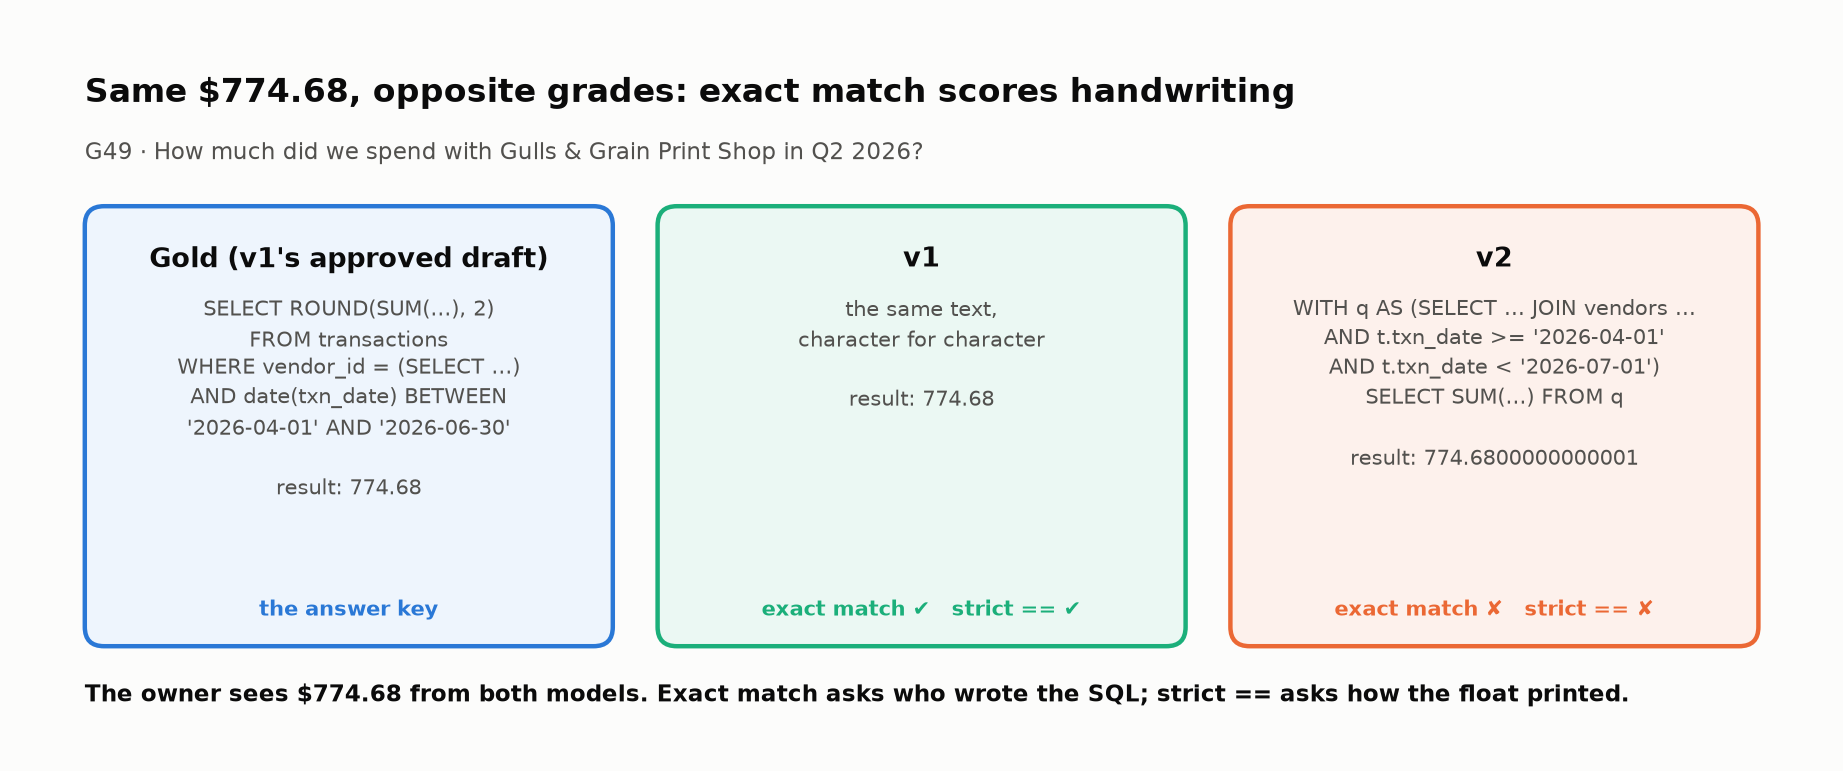

<sub>🖼️ *Same money, three spellings. Exact match checks the spelling and strict `==` checks the float; neither checks the money.*</sub>

▶️ **Run:** one question, its gold SQL and both models' SQL → compare v2's result with the gold's. 🎛️ Then pick `G08`: a reviewer wrote that gold.

In [ ]:
# 🎛️ Pick a question. G08's gold was written by the reviewer; G49's is a v1 draft.
q = "G49"  # @param ["G49", "G08", "G26", "G34"]
print(f"{q}: {golden.question[q]}   (gold written by: {golden.gold_written_by[q]})\n")
for who, sql in [("GOLD", golden.gold_sql[q]), ("v1", RECORDED["v1"][q]), ("v2", RECORDED["v2"][q])]:
    print(f"── {who} SQL ──\n{sql}\n   → result on the demo DB: {run_sql(DEMO, sql)}\n")

In [ ]:
# @title 🔮 Predict: on how many of the 50 golden questions will v1's SQL text match the gold exactly?
v1_exact_matches_will_be = "— pick one —"  # @param ["— pick one —", "A) More than 25", "B) 10 to 25", "C) Under 10"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** scores both models by CI's rule and by exact match → compare the exact-match tiles with the CI tiles.

In [ ]:
MODELS = ("v1", "v2")
gold_demo = {q: run_sql(DEMO, golden.gold_sql[q]) for q in golden.index}
pred_demo = {m: {q: run_sql(DEMO, RECORDED[m][q]) for q in golden.index} for m in MODELS}

layers = {}   # layer name -> {model: pd.Series of per-question pass/fail}; Task 7 plots every layer
# 👀 Look at: exact match compares normalized TEXT; CI compares the result ROWS with Python's ==
layers["Exact match"] = {m: pd.Series({q: normalize_sql(RECORDED[m][q]) == normalize_sql(golden.gold_sql[q])
                                       for q in golden.index}) for m in MODELS}
layers["CI (strict EX)"] = {m: pd.Series({q: strict_match(pred_demo[m][q], gold_demo[q]) for q in golden.index})
                            for m in MODELS}

em, ci = layers["Exact match"], layers["CI (strict EX)"]
gap_ci = ci["v2"].mean() - ci["v1"].mean()
tiles([
    ("CI score: v1", pct(ci["v1"].mean()), f"{ci['v1'].sum()} of {len(golden)}", None),
    ("CI score: v2", pct(ci["v2"].mean()), f"{signed(100 * gap_ci)} pts → gate says BLOCK", "critical"),
    ("Exact match: v1", pct(em["v1"].mean()), f"{em['v1'].sum()} identical SQL texts", None),
    ("Exact match: v2", pct(em["v2"].mean()), f"{em['v2'].sum()} identical SQL texts", "warning"),
])

▶️ **Run:** what exact match measured, and your prediction graded.

In [ ]:
# 💡 Reveal: what is exact match measuring?
insight(
    f"v1 wrote character-identical SQL to the answer key {em['v1'].sum()} times out of {len(golden)}; v2 managed {em['v2'].sum()}",
    f"Exact match says v2 is {100 * (em['v1'].mean() - em['v2'].mean()):.0f} points worse. It is measuring **handwriting**: "
    "v2 writes CTEs and half-open date ranges, v1 writes the compact style the answer key happens to use. "
    "Two careful people almost never write the same query character for character, so a model that does it "
    f"{em['v1'].sum()} times is telling you something about **where the answer key came from**. "
    "Keep that thought until Task 4. Rule of thumb: **never gate on SQL text; it scores style, not answers.**",
    kind="surprise",
)
insight(
    "On accounting questions, the same model scored 20 points lower on exact match than on execution accuracy (BookSQL, NAACL 2024)",
    "BookSQL (Kumar et al., NAACL 2024; IIT Kanpur and Intuit) built 100k question–SQL pairs over accounting databases. "
    "GPT-4 with dynamically chosen examples scored **47.5% exact match but 67.2% execution accuracy** on its test set. "
    "The failures it reports look like this lab's bugs: date filters, wrong transaction- or account-type filters, credit/debit mix-ups.",
    kind="research",
)
_n = int(em["v1"].sum())
quiz("Your prediction: v1's exact matches", v1_exact_matches_will_be, correct="A" if _n > 25 else "B" if _n >= 10 else "C",
     why=f"{_n} of 50, against {em['v2'].sum()} for v2. Nobody writes {_n} queries character for character like someone else by chance.")

✋ **Your turn:** 30 golds are v1's approved drafts; the reviewer wrote the other 20. Split v1's exact matches by author.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_reviewer_em = em["v1"][golden.gold_written_by == "reviewer"].mean()

In [ ]:
# ✋ Your turn: v1's exact-match rate on the golds it drafted itself is printed below.
print(f"v1 exact match on its own 30 drafts: {em['v1'][golden.gold_written_by == 'v1 draft'].mean():.0%}")

my_reviewer_em = ...   # ✏️ v1's exact-match rate on the 20 reviewer-written golds (a fraction, e.g. 0.5)

check("1A · Exact match, split by who wrote the gold", my_reviewer_em, _ref_reviewer_em,
      hint="Same Series, other mask: em['v1'] where golden.gold_written_by == 'reviewer', then .mean().",
      success=f"{_ref_reviewer_em:.0%} on the reviewer's golds vs 100% on v1's own drafts. Exact match measured who wrote the key, not who got the money right.")

🔍 **What just happened:** on its own drafts v1 is graded against itself; v2's CTEs and half-open date ranges almost never match, whatever the numbers say.

🗣️ **Say it to a colleague:** "Exact match on SQL tells you who wrote the answer key, not who got the answer right."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** G49: v2 returns `774.6800000000001`, the gold `774.68`.

**Expected Output:** CI **80%** vs **64%** (−16 pts); exact match **68%** (34) vs **6%** (3).
</details>

In [ ]:
# @title ❓ Quick check: v1 matches the answer key's SQL verbatim on 34 of 50 questions. What should that make you suspect?
answer = "— pick one —"  # @param ["— pick one —", "A) v1 is the stronger model", "B) The answer key was drafted from v1's output", "C) The questions are too easy to tell models apart", "D) Nothing: exact match is working as intended"]
quiz('34 verbatim matches', answer, correct="B",
     why="Two careful people rarely spell a query the same way. 30 of the 50 golds are v1's approved drafts, so v1 is graded against itself.",
     wrong={"A": 'Exact match scores spelling, not money. v2 matched 3 and returns the same totals on most questions.',
          "C": 'Easy questions still have many spellings: v2 matched only 3.',
          "D": "It is comparing text as designed. That's the problem: text isn't the answer."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>Never gate on SQL text: exact match scores who wrote the key, not who got the answer right.</b></font>

</td></tr></table>

---

## Task 2: Same Answer? Write the Comparator

<big><b>Every pass rate from here on goes through one function that decides "same answer".</b></big>

> 🎯 **Goal:** write the **comparator** that decides whether two result sets are the same answer.<br>
> ❓ **The question:** how much of v2's −16 is the comparator's fault?<br>
> 👀 **Watch for:** a lenient rule that passes "return every vendor" queries.

> 📘 **Concept · Execution accuracy (EX)**
>
> **What it is:** run the predicted and the gold query on a database and compare the **result sets** with a **comparator**, the function that decides what "equal" means. EX is the standard metric of text-to-SQL benchmarks (Spider, BIRD, BookSQL).
>
> **What it can't tell you:** whether the query is right on data this database doesn't contain (Task 3), or whether the gold is right (Task 4). And it is only as good as its comparator.
>
> **Anchor:** on G49, v2 returns `774.6800000000001` and the gold `774.68`. Python's `==` says different; any bookkeeper says same.

Every comparator choice is a policy:

<!-- img: comparator-policy.png -->
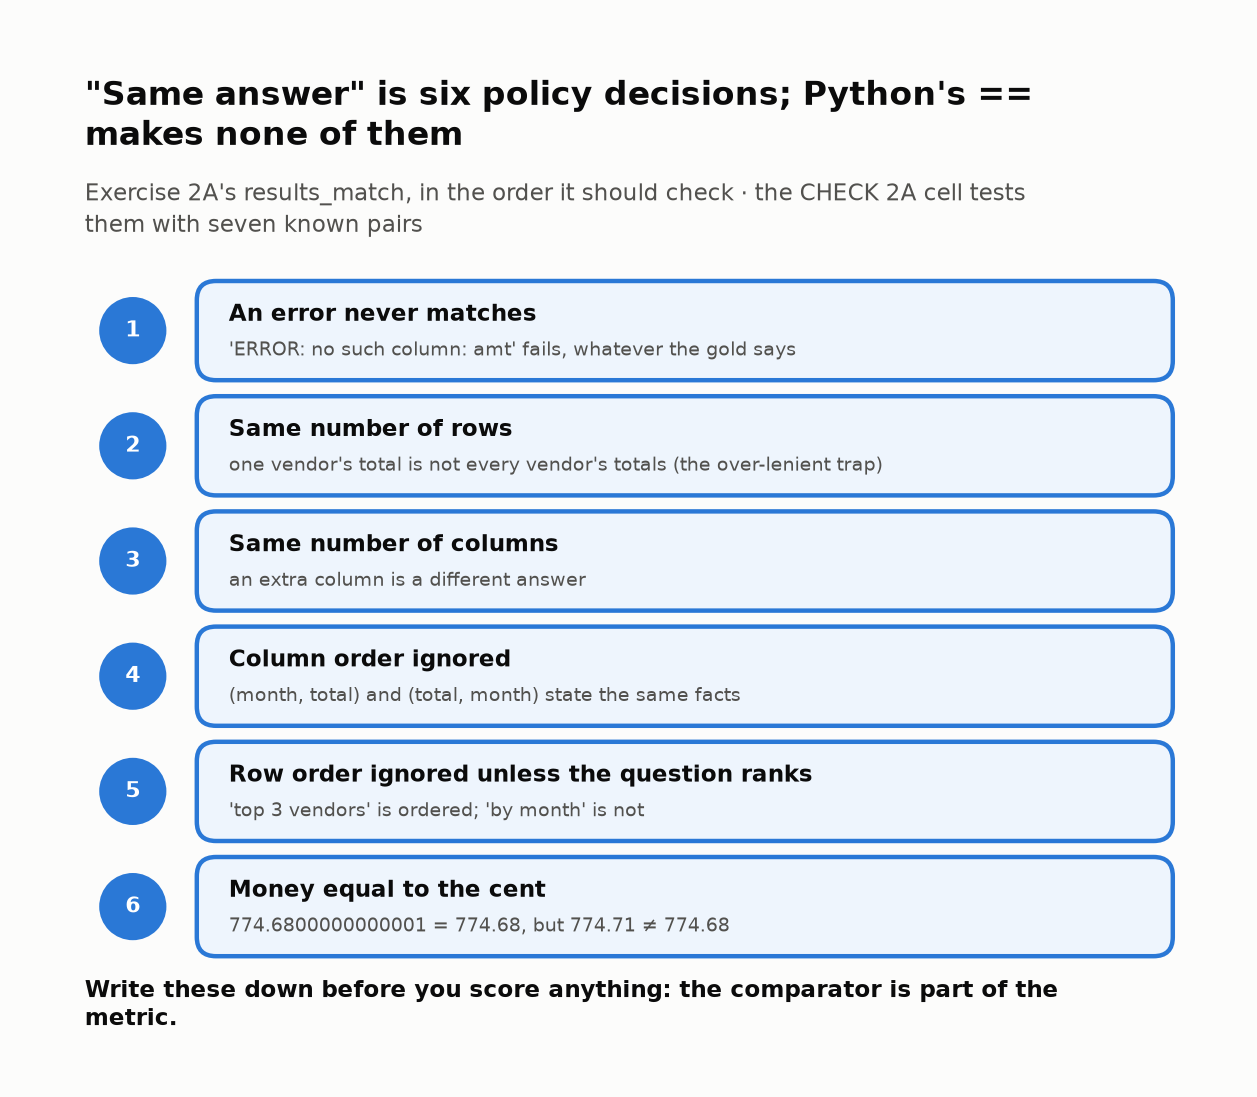

<sub>🖼️ *Exercise 2A in one picture: six decisions, in the order your function should make them.*</sub>

▶️ **Run:** the questions where CI's `==` failed v2 although the money matches.

In [ ]:
fooled = [q for q in golden.index
          if not strict_match(pred_demo["v2"][q], gold_demo[q]) and _reference_results_match(pred_demo["v2"][q], gold_demo[q])]
display(pd.DataFrame({"question": golden.question[fooled],
                      "v2 result": [str(pred_demo["v2"][q])[:48] for q in fooled],
                      "gold result": [str(gold_demo[q])[:48] for q in fooled]}))
print(f"CI's == failed v2 on {len(fooled)} questions where the money matches.")

✋ **Your turn:** **Exercise 2A**, the picture above as code: the scaffolding makes four checks; you write the money rule and the row-order rule.

In [ ]:
# @title 🧰 Reference answer + 7 test cases for Exercise 2A (hidden · spoiler)
results_match = _reference_results_match   # the lab keeps going with the reference comparator


def canon(row):
    """Sort key for a row: floats rounded to the cent, so both sides sort the same way."""
    return repr(tuple(round(c, 2) if isinstance(c, float) else c for c in row))


_CASES_2A = [  # (name, pred, gold, ordered)
    ("float noise", [(774.6800000000001,)], [(774.68,)], False),
    ("columns swapped", [(2824.27, "2026-07"), (2377.46, "2026-08")], [("2026-07", 2824.27), ("2026-08", 2377.46)], False),
    ("rows swapped, no ranking asked", [("B", 2.0), ("A", 1.0)], [("A", 1.0), ("B", 2.0)], False),
    ("rows swapped in a ranking", [("B", 2.0), ("A", 1.0)], [("A", 1.0), ("B", 2.0)], True),
    ("extra row", [("A", 1.0), ("B", 2.0)], [("A", 1.0)], False),
    ("an error", "ERROR: no such column: amt", [(1.0,)], False),
    ("3 cents off", [(774.71,)], [(774.68,)], False),
]
_ref_2A = [_reference_results_match(p, g, o) for _, p, g, o in _CASES_2A]


def _comparator_from(cells_match, same_rows):
    """Your two policy lines inside the fixed scaffolding: errors, row and column counts, column permutations."""
    def comparator(pred, gold, ordered=False):
        if isinstance(pred, str) or isinstance(gold, str) or len(pred) != len(gold):
            return False
        if not gold:
            return True
        if len(pred[0]) != len(gold[0]):
            return False
        return any(same_rows([tuple(r[i] for i in perm) for r in pred], gold, ordered)
                   for perm in itertools.permutations(range(len(gold[0]))))
    return comparator


def _grade_2A(cells_match, same_rows):
    """`...` while a blank is open; otherwise your verdict on each test case (and which ones differ)."""
    try:
        if todo(cells_match(1.0, 1.0)) or todo(same_rows([(1.0,)], [(1.0,)], False)):
            return ...
        mine = _comparator_from(cells_match, same_rows)
        got = [bool(mine(p, g, o)) for _, p, g, o in _CASES_2A]
    except Exception as e:  # noqa: BLE001
        return f"an error: {type(e).__name__}: {e}"
    for (name, *_), y, r in zip(_CASES_2A, got, _ref_2A):
        if y != r:
            print(f"   case '{name}': yours says {'same' if y else 'different'}; it should be {'same' if r else 'different'}")
    return got

In [ ]:
# ✋ Your turn (Exercise 2A): the comparator's two policy lines.
def cells_match(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return ...   # ✏️ numbers: is it the same money?
    return a == b

def same_rows(P, gold, ordered):
    if ordered:   # a ranking: row i must match row i
        return all(cells_match(x, y) for rp, rg in zip(P, gold) for x, y in zip(rp, rg))
    return ...   # ✏️ no ranking asked: row order must not matter (canon(row) is a sort key)

check("2A · Your comparator on 7 known pairs", _grade_2A(cells_match, same_rows), _ref_2A,
      hint="Money is equal within a cent, not exactly: 774.6800000000001 is $774.68. For rows, put both sides in the same order (key=canon), then the ranking comparison applies.",
      success="7 of 7: float noise, swapped columns and swapped rows are the same answer; an extra row, an error, 3 cents or a re-ordered ranking are not. These are your comparator's unit tests.")

In [ ]:
# @title 🔮 Predict: an over-lenient comparator passes a prediction if every gold value appears *somewhere* in its rows. Whose score rises?
lenient_rule_helps = "— pick one —"  # @param ["— pick one —", "A) Only v1's", "B) Both, v2's more", "C) Both, v1's more", "D) Only v2's"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** the same recorded SQL under three comparators → read the chart title.

In [ ]:
COMPARATORS = {"strict ==  (CI today)": strict_match, "results_match (fair)": results_match,
               "over-lenient": lenient_match}
# 👀 Look at: same recorded SQL, same database; only the definition of "same answer" changes between rows
cmp_scores = pd.DataFrame({name: {m: sum(fn(pred_demo[m][q], gold_demo[q], golden.ordered[q]) for q in golden.index)
                                  for m in MODELS} for name, fn in COMPARATORS.items()}).T
display(cmp_scores.rename(columns=lambda m: f"{m} passes (of {len(golden)})"))

layers["EX (one DB)"] = {m: pd.Series({q: results_match(pred_demo[m][q], gold_demo[q], golden.ordered[q])
                                       for q in golden.index}) for m in MODELS}
ex = layers["EX (one DB)"]
plot_comparators(cmp_scores, f"The comparator alone moves v2 by {100 * (ex['v2'].mean() - ci['v2'].mean()):.0f} points")

▶️ **Run:** what the comparator changed, and your prediction graded.

In [ ]:
# 💡 Reveal: what did the comparator change?
lenient_gain = {m: cmp_scores.loc["over-lenient", m] - cmp_scores.loc["results_match (fair)", m] for m in MODELS}

nofilter = [q for q in golden.index if any(lenient_match(pred_demo[m][q], gold_demo[q]) and not results_match(pred_demo[m][q], gold_demo[q], golden.ordered[q]) for m in MODELS)]
insight(
    f"A fair comparator turns v2's −{100 * (ci['v1'].mean() - ci['v2'].mean()):.0f}-point 'regression' into "
    f"{signed(100 * (ex['v2'].mean() - ex['v1'].mean()))}, and the over-lenient one inflates both models",
    f"With a fair comparator v1 scores {pct(ex['v1'].mean())} and v2 {pct(ex['v2'].mean())}: {len(fooled)} of v2's CI failures were float noise "
    f"or column order. The over-lenient rule adds {lenient_gain['v1']} pass(es) to v1 and {lenient_gain['v2']} to v2, "
    f"from queries like {nofilter[0]} that return **every** vendor's total, the right one included. "
    "The comparator is part of the metric. Rule of thumb: **unit-test your comparator with known-same and known-different "
    "pairs before you trust a single score it produces.**",
)
_g = {m: int(v) for m, v in lenient_gain.items()}
quiz("Your prediction: who gains from the lenient rule", lenient_rule_helps,
     correct=("C" if _g["v1"] > _g["v2"] else "B") if min(_g.values()) > 0 else ("A" if _g["v1"] > 0 else "D"),
     why=f"Both: v1 +{_g['v1']}, v2 +{_g['v2']}. Leniency rewards queries that return every vendor's total, the right one included.")

🔍 **What just happened:** strict `==` failed 5 correct v2 answers: 3 with float noise (v2 doesn't `ROUND`), 2 with columns swapped. <mark>The gate still says BLOCK</mark> (−6 vs −2 allowed), and every number so far comes from one database.

🗣️ **Say it to a colleague:** "Before you quote me a pass rate, show me the comparator's test cases."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** passes v1 / v2: strict == **40 / 32** · fair **40 / 37** · over-lenient **45 / 40**.

**Expected Output:** chart *"The comparator alone moves v2 by 10 points"*.
</details>

In [ ]:
# @title ❓ Quick check: the over-lenient rule raised both scores. Why is it dangerous?
answer = "— pick one —"  # @param ["— pick one —", "A) It is slower than strict equality", "B) It fails correct answers that have float noise", "C) It is fine: extra rows never hurt an owner", "D) It passes queries that return every vendor's total, the right one included"]
quiz('The lenient comparator', answer, correct="D",
     why='G04 asks about one landlord and gets 14 rows, one per vendor. The right number is in there, so the lenient rule passes it; the owner reads a table of everyone.',
     wrong={"A": "Speed isn't the issue; what it calls 'same' is.",
          "B": "That's strict ==. Lenient rounds to the cent, so float noise passes.",
          "C": "An owner who asked about one vendor and got fourteen can't tell which is the answer."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>The comparator is part of the metric: unit-test it on known-same and known-different pairs first.</b></font>

</td></tr></table>

---

## Task 3: One Database Is One Test Case

<big><b>A query that's right only on tidy demo books ships to owners whose books have voids, credits and look-alike vendor names.</b></big>

> 🎯 **Goal:** run every query on a **suite** of databases that hold the edge cases real books have.<br>
> ❓ **The question:** how many of the passes so far were luck?<br>
> 👀 **Watch for:** what the stricter suite does when the *gold* is wrong.

> 📘 **Concept · Test-suite accuracy**
>
> **What it is:** run the predicted and the gold query on a **suite** of databases and pass only if they match on *every* one (Zhong, Yu & Klein, 2020). Each database comes from a **fuzzer**, code that copies the books and injects one kind of edge case. This suite: the demo DB, 7 fuzzed copies, and a "kitchen sink" copy with all of them.
>
> **What it can't tell you:** whether the gold is right. It proves "matches the gold everywhere", not "is right", and it is an upper bound: a query can pass every database you have and still be wrong (Challenge 2).
>
> **Anchor:** if the demo books contain no voided bills, a query that forgets `status = 'posted'` returns the right total: a **lucky pass**. A copy with voided bills exposes it.

<!-- img: test-suite.png -->
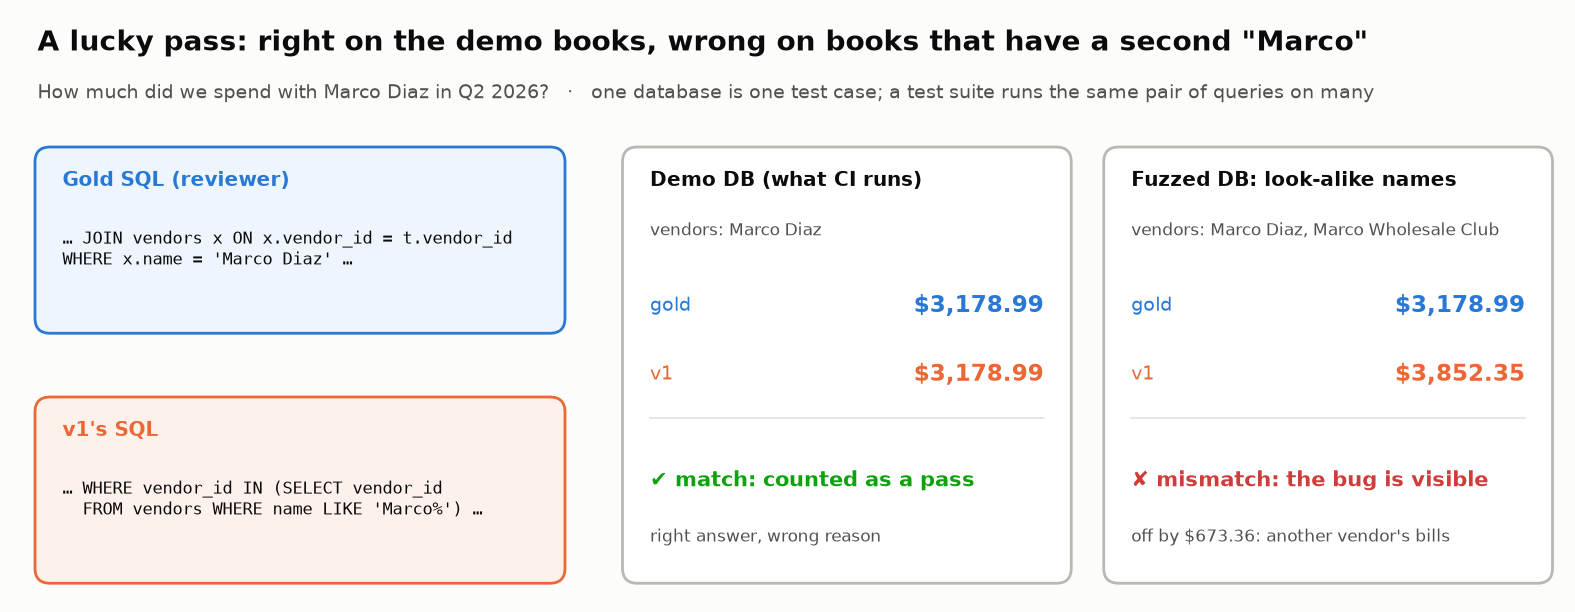

<sub>🖼️ *A lucky pass, caught. The demo DB happens to have one vendor whose name starts with "Marco"; real books can have two.*</sub>

<!-- img: comic-demo-db.png -->
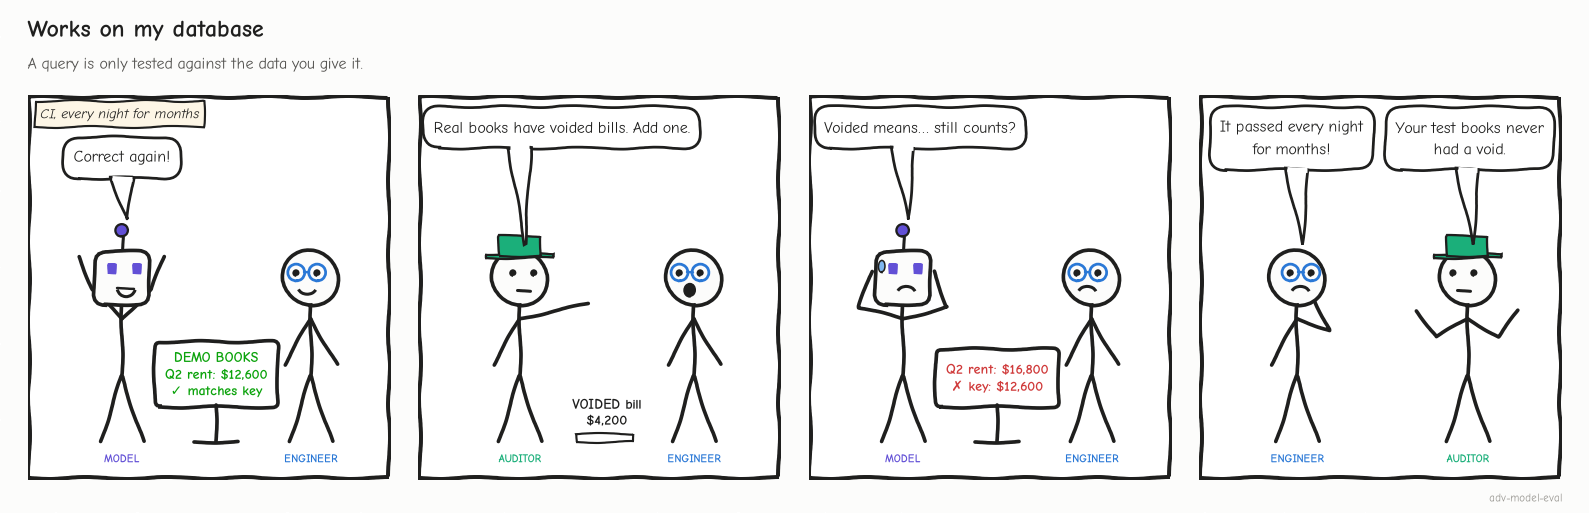

<sub>😄 *If the edge case isn't in your test data, your eval can't see the bug.*</sub>

✋ **Your turn:** **Exercise 3A**, a fuzzer. It copies about 1 in 4 posted rows; you choose each copy's status. <mark>No correct total may change.</mark>

In [ ]:
# @title 🧰 add_txn() + the property grader for Exercise 3A (hidden · spoiler)
class _Blank(Exception):
    pass


def add_txn(con, txn_date, txn_type, account_id, vendor_id, customer_id, amount, status):
    """Insert one transaction (with a new txn_id) into a copy of the books."""
    if todo(status):
        raise _Blank()
    con.execute("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
                (_next_id(con), txn_date, txn_type, account_id, vendor_id, customer_id, amount, status, None, None, "fuzzed"))


_3A_exposed = 0


def _grade_3A(fuzzer, seed=3):
    """`...` while the blank is open; "ok" if the fuzzer has the four properties of a good one; otherwise what's wrong."""
    global _3A_exposed
    db = clone_db(DEMO)
    top = db.execute("SELECT MAX(txn_id) FROM transactions").fetchone()[0]
    try:
        fuzzer(db, random.Random(seed))
    except _Blank:
        return ...
    except Exception as e:  # noqa: BLE001
        return f"your fuzzer raised {type(e).__name__}: {e}"
    added = db.execute("SELECT COUNT(*) FROM transactions WHERE txn_id > ?", (top,)).fetchone()[0]
    if added < 20:
        return f"it added only {added} rows"
    changed = [q for q in golden.index if not _reference_results_match(report_engine(q, db), report_engine(q, DEMO))]
    if changed:
        return f"the right answer changed on {len(changed)} golden questions (e.g. {changed[0]}): those rows count in real totals"
    exposed = [(m, q) for q in golden.index for m in ("v1", "v2")
               if _reference_results_match(run_sql(DEMO, RECORDED[m][q]), report_engine(q, DEMO))
               and not _reference_results_match(run_sql(db, RECORDED[m][q]), report_engine(q, db))]
    if not exposed:
        return "valid, but it exposes no lucky pass"
    _3A_exposed = len(exposed)
    return "ok"

In [ ]:
# ✋ Your turn (Exercise 3A): a fuzzer for voided and draft entries.
def fuzz_void_and_draft(con, rng):
    posted = con.execute("SELECT txn_date, txn_type, account_id, vendor_id, customer_id, amount FROM transactions "
                         "WHERE status = 'posted' AND txn_type IN ('bill','expense','invoice','sales_receipt')").fetchall()
    for d, typ, acct, vid, cid, amt in posted:
        if rng.random() < 0.25:
            status = ...   # ✏️ a status the metric glossary says no total may count
            add_txn(con, d, typ, acct, vid, cid, round(amt * rng.uniform(0.5, 1.5), 2), status)

check("3A · A void/draft fuzzer", _grade_3A(fuzz_void_and_draft), "ok",
      hint="The glossary counts POSTED rows only. A copy marked 'void' or 'draft' (rng.choice can pick one) must leave every right answer alone.",
      success=f"Valid and useful: your copies change no correct total and expose {_3A_exposed} lucky passes. The suite below uses the reference version of this fuzzer.")

In [ ]:
# @title 🔮 Predict: on all 9 databases, what happens to v1's 40 one-database passes and v2's 37?
suite_effect_will_be = "— pick one —"  # @param ["— pick one —", "A) All survive", "B) Both lose several", "C) v1 loses a few, v2 none"]
print("🔮 Locked in. Graded after the reveal.")

▶️ **Run:** builds the suite (demo + 7 fuzzed copies + a kitchen sink) and re-grades both models → read the tiles, then the chart title.

In [ ]:
SUITE = build_suite(FUZZERS)
gold_suite = {q: run_on(SUITE, golden.gold_sql[q]) for q in golden.index}
pred_suite = {m: {q: run_on(SUITE, RECORDED[m][q]) for q in golden.index} for m in MODELS}

# 👀 Look at: one mismatch on ANY database fails the question
def passes_everywhere(m, q, reference):
    return all(results_match(pred_suite[m][q][db], reference[q][db], golden.ordered[q]) for db in SUITE)

layers["Test suite"] = {m: pd.Series({q: passes_everywhere(m, q, gold_suite) for q in golden.index}) for m in MODELS}
ts = layers["Test suite"]
lucky = {m: [q for q in golden.index if ex[m][q] and not ts[m][q]] for m in MODELS}

# which fuzzer exposed each lost pass (a pass can be exposed by several)
expose = pd.DataFrame({m: {db: sum(not results_match(pred_suite[m][q][db], gold_suite[q][db], golden.ordered[q])
                                   for q in lucky[m]) for db in SUITE if db != "demo"} for m in MODELS})
tiles([
    ("Databases in the suite", len(SUITE), "demo + 7 fuzzed + kitchen sink", None),
    ("v1: EX → test suite", f"{pct(ex['v1'].mean())} → {pct(ts['v1'].mean())}", f"{len(lucky['v1'])} passes lost", "warning"),
    ("v2: EX → test suite", f"{pct(ex['v2'].mean())} → {pct(ts['v2'].mean())}", f"{len(lucky['v2'])} passes lost", "warning"),
    ("Gap (v2 − v1)", f"{signed(100 * (ts['v2'].mean() - ts['v1'].mean()))} pts", "it got wider", "critical"),
])
plot_exposure(expose, lucky)

▶️ **Run:** one lucky pass up close (G08), the reveal, and your prediction graded.

In [ ]:
# 🔎 One lucky pass up close
ex_q = "G08"
print(f"{ex_q}: {golden.question[ex_q]}")
v1_sql = RECORDED["v1"][ex_q]
start = v1_sql.index("(SELECT")
print(f"  v1 picks the vendor with: {v1_sql[start:v1_sql.index(')', start) + 1]}")
for db in ("demo", "sibling_vendors"):
    print(f"  {db:>16}: gold {gold_suite[ex_q][db]}   v1 {pred_suite['v1'][ex_q][db]}")
insight(
    f"The suite removed {len(lucky['v1'])} of v1's passes and {len(lucky['v2'])} of v2's, and the gap widened to "
    f"{signed(100 * (ts['v2'].mean() - ts['v1'].mean()))} points",
    f"{ex_q} is a textbook lucky pass: v1 matched vendors with `LIKE 'Marco%'`, which is right only while the books hold one "
    "vendor whose name starts with \"Marco\". The test suite is stricter in **both** directions, though: it fails a "
    "prediction whenever it disagrees with the gold on *any* database. If the gold itself is wrong on an edge case, "
    "a correct model now fails. Rule of thumb: **a test suite removes lucky passes, and it makes a wrong answer key "
    "louder, not quieter.**",
    kind="surprise",
)
insight(
    "Single-database execution accuracy has false positives; a distilled suite of databases removes most of them (Zhong et al., 2020)",
    "Zhong, Yu & Klein (EMNLP 2020) generated many random databases per question and distilled a small suite chosen to "
    "tell the gold query apart from slightly altered versions of it. Test-suite accuracy approximates **semantic** accuracy (does the query mean "
    "the same thing as the gold?), but it remains an upper bound: a query can still pass every database in the suite and be wrong.",
    kind="research",
)
_lost = {m: len(lucky[m]) for m in MODELS}
quiz("Your prediction: what the suite does", suite_effect_will_be,
     correct="A" if not any(_lost.values()) else "C" if not _lost["v2"] else "B",
     why=f"v1 lost {_lost['v1']} passes, v2 lost {_lost['v2']}: each fuzzed copy holds the trigger for one kind of bug the demo books lack.")

✋ **Your turn:** break a lucky pass yourself. One look-alike vendor is all it takes.

In [ ]:
# @title 🧰 Reference answer for the exercise below (hidden · spoiler)
_ref_vendor = "Marco Polo Roasters"


def _breaks_g08(name):
    """Add vendor `name` with one $250 posted Q2 bill. Does v1's G08 total go wrong while the truth holds?"""
    db = clone_db(DEMO)
    db.execute("INSERT INTO vendors VALUES (999, ?, 0)", (str(name),))
    db.execute("INSERT INTO transactions VALUES (?,?,?,?,?,?,?,?,?,?,?)",
               (_next_id(db), "2026-05-12 10:00:00", "bill", 22, 999, None, 250.0, "posted", None, None, "exercise 3B"))
    return not results_match(run_sql(db, RECORDED["v1"]["G08"]), report_engine("G08", db))

In [ ]:
# ✋ Your turn: v1 finds Marco Diaz with  name LIKE 'Marco%'.  Name ONE new vendor that, with a single
#    $250 bill in Q2, makes v1's G08 total wrong while the report engine's stays right.
my_vendor = ...   # ✏️ a vendor name (a string)

check("3B · One vendor breaks a lucky pass", my_vendor, ok=not todo(my_vendor) and _breaks_g08(my_vendor),
      hint="LIKE 'Marco%' matches every name that starts with Marco. A second vendor with that prefix is swept into v1's total.",
      success=f"{my_vendor!r} adds $250 to v1's answer and nothing to the truth. On the demo books v1 was right by luck: they hold one Marco.")

🔍 **What just happened:** each fuzzed copy holds one bug's trigger, so a query right by coincidence now disagrees with the gold, and fails whichever side is wrong.

🗣️ **Say it to a colleague:** "One database is one test case. Our CI ran one test."

<details><summary>📋 <b>Checkpoint</b>: compare with the expected output</summary>

**Checkpoint ✅** G08 on `sibling_vendors`: gold `3178.99`, v1 `3852.35`.

**Expected Output:** v1 **80% → 68%** (6 lost); v2 **74% → 60%** (7 lost); gap **−8 pts**. `no_vendor` exposes nothing: the one query it should catch has a gold with the same bug.
</details>

In [ ]:
# @title ❓ Quick check: the gold for a question is wrong on one edge case. What does the stricter suite do?
answer = "— pick one —"  # @param ["— pick one —", "A) Fails the model that gets the edge case right", "B) Nothing: a few wrong golds average out", "C) Flags the wrong gold for review"]
quiz('A wrong gold in the suite', answer, correct="A",
     why='The suite compares with the gold on every database, so a correct answer that disagrees with a wrong gold fails. Stricter grading makes a wrong key louder.',
     wrong={"B": "Each wrong gold fails a specific model, every time. Errors in the key don't cancel; they pick a side.",
          "C": "The suite can't tell which side is wrong. That takes an independent source of truth (Task 4)."})

<table><tr><td>

🔑 **Key takeaway**<br>
<font size="5" color="#2a78d6"><b>One database is one test case: fuzz the edge cases real books have, and remember the suite still trusts the gold.</b></font>

</td></tr></table>

---

## 🔑 Part 1 in three lines

1. **Grade answers, not SQL text:** exact match scored who wrote the key.
2. **The comparator is part of the metric:** a fair one moved v2 by 10 points.
3. **One database is one test case:** the suite removed 13 lucky passes, and the gap *widened* to −8.

▶️ **Run:** your Part 1 score, and what to revisit.

In [ ]:
scoreboard()

<center><font size="5"><b>➡️ Continue in Part 2: who checks the answer key?</b></font></center>

<center>

[![Open Part 2 In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/varoonsahgal/adv-model-eval-student/blob/main/labs/04c-text-to-sql-analytics-part-2-lab.ipynb)

</center>

